# B2 · DS2 hardware models profile

## Overview
DS2 is what the controller actually applied, so before we model drift we need to know which parameters move, how the controller moves them and how often it turns an update down ([Phase 01, B2](../../docs/phases/01_eda.md#b2-ds2-hardware-models)). Since `output_info` old and new equal DS2 (A3), we read controller behaviour from the run map wherever `output_info` carries the parameter, and use DS2 itself ([datasheet 2](../../docs/datasheets/02_hardware_models.md)) for the untracked writes, DC bias up to 2026-05-25, the parameters `output_info` doesn't carry and the static layer.

**Question.** Which parameters move, how does the controller move them, and how often does it reject an update?

**Method.** We tie each snapshot to the run and stage that wrote it, and check writer attribution, untracked writes and the static layer (section 1). Then we explain the 1q rows with no step id before anything counts as a rejection (section 2), and profile the dynamic parameters and their writers (section 3). Section 4 measures reject shares and step sizes per param and writes the controller rows to `noise_floor.parquet`. Last, we screen for coherent jumps, a shared per-run offset and a change at the 2026 thermal cycle (section 5). Steps stay in native units here - [b3c](b3c_ds1_noise_1q.ipynb) compares them with measurement noise.


In [1]:
import json
import re
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from qpu_drift import periods
from qpu_drift.derived.noise import write_noise_rows
from qpu_drift.derived.run_map import load_run_entities, load_run_map, load_run_results
from qpu_drift.derived.run_map.constants import STEPS_1Q
from qpu_drift.paths import OUTPUT_INFO, REPO_ROOT
from qpu_drift.sources.hardware_models import load_index, load_paths, load_values
from qpu_drift.sources.output_info import iter_files

pd.set_option("display.max_rows", 200, "display.max_columns", 30, "display.width", 250, "display.max_colwidth", 80)
idx = load_index()
values = load_values()
paths = load_paths()
runs = load_run_map()
ent = load_run_entities()
ids = load_run_results()

snaps = idx.sort_values("timestamp")["timestamp"].reset_index(drop=True)
pos = pd.Series(snaps.index, index=snaps)
FIRST, LAST = snaps.iloc[0], snaps.iloc[-1]
TRACKED = ["calibrate_1q", "calibrate_2q", "mixer_calibration"]
SHORT = {"calibrate_1q": "1q", "calibrate_2q": "2q", "mixer_calibration": "mixer", "benchmarking": "bm"}
print(f"{len(snaps)} snapshots {FIRST} to {LAST}; {len(values)} value runs on {values['path'].nunique()} paths, "
      f"{len(paths)} templates")
print("runs per routine:", runs["routine"].value_counts().to_dict())
print("entity rows per routine:", ent["routine"].value_counts().to_dict())


def rsd(s: pd.Series) -> float:
    """Robust sd: 1.4826 x the median absolute deviation."""
    return 1.4826 * (s - s.median()).abs().median()


def events(values: pd.DataFrame) -> pd.DataFrame:
    """Every DS2 event after the first snapshot: a value change, a path appearing or reappearing, or a path disappearing."""
    v = values[["path", "path_template", "entity", "valid_from_ts", "valid_to_ts"]].copy()
    v["i0"] = pos.reindex(v["valid_from_ts"]).to_numpy()
    v["i1"] = pos.reindex(v["valid_to_ts"].fillna(LAST)).to_numpy()
    v = v.sort_values(["path", "i0"])
    prev_i1 = v.groupby("path")["i1"].shift()
    starts = v[v["i0"] > 0].assign(kind=np.where(prev_i1[v["i0"] > 0] == v.loc[v["i0"] > 0, "i0"] - 1, "change",
                                                 np.where(prev_i1[v["i0"] > 0].isna(), "appear", "reappear")))
    next_i0 = v.groupby("path")["i0"].shift(-1)
    gone = v[(v["i1"] < len(snaps) - 1) & (next_i0 != v["i1"] + 1)]
    gone = gone.assign(i0=gone["i1"] + 1, kind="disappear")
    ev = pd.concat([starts, gone])[["path", "path_template", "entity", "i0", "kind"]]
    ev["at"] = snaps.to_numpy()[ev["i0"].astype(int)]
    return ev.drop(columns="i0").sort_values(["at", "path"]).reset_index(drop=True)


ev = events(values)
print(f"{len(ev)} DS2 events after the first snapshot:", ev["kind"].value_counts().to_dict())
ROUTINES = Path.home() / "git" / "oqc-calibration-routines"


def git(*args: str) -> str:
    """Run git in the local oqc-calibration-routines clone."""
    return subprocess.run(["git", "-C", ROUTINES, *args], capture_output=True, text=True, check=True).stdout


def show_code(file: str, *patterns: str) -> None:
    """Print the HEAD lines of a routines script matching any pattern, and the commit that first added each pattern."""
    f = f"calibration_routines/scripts/{file}"
    print(f"{file} at", git("log", "-1", "--format=%h %ci", "--", f), end="")
    print(git("grep", "-n", "-E", "|".join(patterns), "HEAD", "--", f).replace(f"HEAD:{f}:", "  "), end="")
    for p in patterns:
        first = git("log", "--reverse", "--format=%h %ci", "-G", p, "--", f).splitlines()
        print(f"  first commit matching {p!r}: {first[0] if first else 'none'}")


4603 snapshots 2025-01-01 08:00:13 to 2026-08-18 09:13:31; 686613 value runs on 8460 paths, 286 templates
runs per routine: {'calibrate_2q': 2007, 'calibrate_1q': 1298, 'benchmarking': 663, 'mixer_calibration': 655}
entity rows per routine: {'calibrate_2q': 320575, 'mixer_calibration': 167680, 'calibrate_1q': 124608}


678324 DS2 events after the first snapshot: {'change': 678153, 'appear': 159, 'disappear': 12}


## 1. Provenance and strata

First we tie each snapshot to whatever wrote it. A snapshot's stage is the routine whose `snap_after` it is, or `none`. A no-run snapshot that is some run's `snap_before` is matched to the first run it precedes, with the gap to that run's start and the time since the last run's `snap_after` - a gap of seconds means a pre-run save.

In [2]:
land = runs.dropna(subset=["snap_after"]).groupby("snap_after").agg(
    routines=("routine", lambda s: "+".join(sorted(set(s)))), n_runs=("routine", "size"), window=("window", "first"))
before_of = set(runs["snap_before"].dropna())
snap = pd.DataFrame({"at": snaps}).join(land, on="at")
snap["stage"] = snap["routines"].fillna("none")
snap["is_snap_before"] = snap["at"].isin(before_of)
snap["n_events"] = snap["at"].map(ev.groupby("at").size()).fillna(0).astype(int)
print("snapshots by the routine(s) whose snap_after they are, and whether they are also some run's snap_before:")
display(snap.groupby(["stage", "is_snap_before"]).agg(snapshots=("at", "size"), with_events=("n_events", lambda s: (s > 0).sum()),
                                                        events=("n_events", "sum"), max_events=("n_events", "max")))
print("snapshots that are the snap_after of more than one run:")
display(snap[snap["n_runs"] > 1][["at", "routines", "n_runs", "n_events"]])
first_run = runs.dropna(subset=["snap_before"]).sort_values("start").groupby("snap_before")[["routine", "start"]].first()
pre = snap.assign(prev_run_snapshot=snap["at"].where(snap["stage"] != "none").shift().ffill())
pre = pre[(pre["stage"] == "none") & pre["is_snap_before"]].join(first_run, on="at")
pre = pre.assign(seconds_to_run=(pre["start"] - pre["at"]).dt.total_seconds(),
                 hours_since_prev_run_snapshot=(pre["at"] - pre["prev_run_snapshot"]).dt.total_seconds() / 3600)
print("no-run snapshots that are a run's snap_before, by the first run they precede:")
display(pre.groupby("routine").agg(snapshots=("at", "size"), median_s_to_run=("seconds_to_run", "median"),
                                   max_s_to_run=("seconds_to_run", "max"),
                                   median_h_since_prev_run_snapshot=("hours_since_prev_run_snapshot", "median")).round(1))


snapshots by the routine(s) whose snap_after they are, and whether they are also some run's snap_before:


snapshots  with_events  events  max_events
stage             is_snap_before                                            
benchmarking      False                 542          539   25933          62
calibrate_1q      False                   7            7    2818         405
                  True                 1114         1100  438597         412
calibrate_2q      False                 580          561   66147         243
                  True                  537          536   63259         128
mixer_calibration False                   7            6     919         242
                  True                  542          542   75164         228
none              False                 138           13    1924         806
                  True                 1136           26    3563         628

snapshots that are the snap_after of more than one run:


,at,routines,n_runs,n_events


no-run snapshots that are a run's snap_before, by the first run they precede:


,snapshots,median_s_to_run,max_s_to_run,median_h_since_prev_run_snapshot
routine,,,,
benchmarking,5,7.0,564.0,0.8
calibrate_1q,579,2.0,15.0,9.6
calibrate_2q,3,6.0,7.0,2.6
mixer_calibration,549,6.0,21.0,9.8


**Results.**

- No snapshot is the `snap_after` of more than one run. Stage `none` has 138 snapshots that aren't a run's `snap_before` (13 with events, 1,924 events) and 1,136 that are (26 with events, 3,563 events).
- Those 1,136 sit just before the run they precede (median and max seconds before it, median hours since the last run snapshot): `calibrate_1q` 579 (2.0 s, 15.0 s, 9.6 h), `mixer_calibration` 549 (6.0 s, 21.0 s, 9.8 h), `benchmarking` 5 (7.0 s, 564.0 s, 0.8 h), `calibrate_2q` 3 (6.0 s, 7.0 s, 2.6 h). So they're pre-run saves.

Then we count every DS2 value change per template (one template is one parameter) and stage. A template's owner is the tracked stage with the most changes, so an owner that disagrees with `paths.writer_stage` is an anomaly.


In [3]:
chg = ev[ev["kind"] == "change"].copy()
chg["stage"] = chg["at"].map(snap.set_index("at")["stage"])
att = pd.crosstab(chg["path_template"], chg["stage"])
att.columns.name = None
att.insert(0, "changes", att.sum(axis=1))
att["writer_stage (paths)"] = att.index.map(paths.set_index("path_template")["writer_stage"].map(lambda s: ", ".join(dict.fromkeys(s))))
print("DS2 value changes per template, by the stage whose snap_after they land on ('none' = no run's snap_after):")
display(att.sort_values("changes", ascending=False))

DS2 value changes per template, by the stage whose snap_after they land on ('none' = no run's snap_after):


,changes,benchmarking,calibrate_1q,calibrate_2q,mixer_calibration,none,writer_stage (paths)
path_template,,,,,,,
model.pulse_channels{Ch*.Q*.Q*.cross_resonance}.pulse_channel.frequency,66318,0,65856,0,0,462,calibrate_1q
model.pulse_channels{Ch*.Q*.Q*.cross_resonance_cancellation}.pulse_channel.frequency,66318,0,65856,0,0,462,calibrate_1q
model.quantum_devices{Q*}.mean_z_map_args,52707,17129,35186,0,0,392,"calibrate_1q, benchmarking"
model.pulse_channels{Ch*.Q*.drive}.pulse_channel.scale,35403,0,35153,0,0,250,calibrate_1q
model.error_mitigation.readout_mitigation.linear{*}{0|1},34853,0,34634,0,0,219,calibrate_1q
model.error_mitigation.readout_mitigation.linear{*}{1|1},34853,0,34634,0,0,219,calibrate_1q
model.error_mitigation.readout_mitigation.linear{*}{1|0},34713,0,34495,0,0,218,calibrate_1q
model.error_mitigation.readout_mitigation.linear{*}{0|0},34713,0,34495,0,0,218,calibrate_1q
model.quantum_devices{Q*}.pulse_hw_x_pi_2{amp},34337,0,34134,0,0,203,calibrate_1q


**Results.**

- `paths.writer_stage` agrees with where the changes land. Each template's changes are on one of its writer stages or on `none`. Only `mean_z_map_args` lists two stages: `calibrate_1q` and `benchmarking`, where it changes 17,129 times (next cell).
- The readout fields have no writer. `pulse_measure` amp and width, the measure and acquire channel `frequency` and the `second_state` channel change only on `none`. The exceptions are on `mixer_calibration`: 32 `measure_acquire` delay changes, 32 width changes and 23 `pulse_measure` width changes.
- Some dynamic templates aren't in `output_info`: CR and CRC `pulse_channel.frequency`, 65,856 changes each on `calibrate_1q`, and `phase_comp_target_zx_pi_4`, 32,321 on `calibrate_2q`.

Changes on any tracked stage other than the owner are anomalies too, and snapshots on stage `none` with events are joined to `UNTRACKED_DS2`.


In [4]:
UNTR = pd.DataFrame(periods.UNTRACKED_DS2).set_index("at")
kinds = ev.pivot_table(index="at", columns="kind", values="path", aggfunc="size", fill_value=0)
un = snap[(snap["stage"] == "none") & (snap["n_events"] > 0)].set_index("at")[["is_snap_before", "n_events"]].join(kinds)
un["top_templates"] = [", ".join(f"{k.replace('model.', '')} {v}" for k, v in
                                 chg.loc[chg["at"] == a, "path_template"].value_counts().head(3).items()) for a in un.index]
un = un.join(UNTR[["kind", "restores"]].rename(columns={"kind": "register"}))
un["in_outage"] = periods.within(un.index, *periods.OUTAGES)
un["snap_before_of"] = [f"{r.routine} {r.start}" if isinstance(r.routine, str) else "" for r in
                        first_run.reindex(un.index).itertuples()]
print(f"{len(un)} snapshots with DS2 events that are no run's snap_after; {un['register'].notna().sum()} of "
      f"{len(UNTR)} UNTRACKED_DS2 entries among them, {len(UNTR) - UNTR.index.isin(un.index).sum()} entries not found:")
display(un)

owner = att.drop(columns=["changes", "writer_stage (paths)", "none"]).idxmax(axis=1)
tr = chg[chg["stage"] != "none"].assign(owner=lambda d: d["path_template"].map(owner))
odd = tr[tr["stage"] != tr["owner"]].groupby(["path_template", "owner", "stage"]).agg(
    changes=("path", "size"), paths=("path", "nunique"), snapshots=("at", "nunique"), first=("at", "min"), last=("at", "max"))
print("changes landing on a tracked stage other than the template's main (owner) stage:")
display(odd)


39 snapshots with DS2 events that are no run's snap_after; 12 of 12 UNTRACKED_DS2 entries among them, 0 entries not found:


,is_snap_before,n_events,appear,change,disappear,top_templates,register,restores,in_outage,snap_before_of
at,,,,,,,,,,
2025-02-03 19:05:14,True,24,0,24,0,"pulse_channels{Ch*.Q*.Q*.cross_resonance}.pulse_channel.scale 6, pulse_chann...",NaN,NaT,False,mixer_calibration 2025-02-03 19:05:21
2025-02-12 11:18:02,False,17,0,17,0,pulse_channels{Ch*.Q*.drive}.pulse_channel.scale 17,NaN,NaT,False,
2025-02-12 13:40:14,False,387,0,387,0,pulse_channels{Ch*.Q*.Q*.cross_resonance_cancellation}.pulse_channel.frequen...,unmatched,NaT,False,
2025-02-12 17:34:10,False,141,0,141,0,"pulse_channels{Ch*.Q*.Q*.cross_resonance}.pulse_channel.scale 30, pulse_chan...",unmatched,NaT,False,
2025-02-12 19:05:13,True,145,0,145,0,"pulse_channels{Ch*.R*.acquire}.pulse_channel.frequency 32, pulse_channels{Ch...",NaN,NaT,False,mixer_calibration 2025-02-12 19:05:20
2025-02-13 19:05:14,True,36,0,36,0,"quantum_devices{Q*}.pulse_measure{width} 28, pulse_channels{Ch*.Q*.second_st...",NaN,NaT,False,mixer_calibration 2025-02-13 19:05:20
2025-02-14 08:00:13,True,7,0,7,0,"quantum_devices{Q*}.mean_z_map_args 2, quantum_devices{Q*}.pulse_measure{amp...",NaN,NaT,False,calibrate_1q 2025-02-14 08:00:20
2025-02-17 14:18:18,True,8,0,8,0,"pulse_channels{Ch*.Q*.Q*.cross_resonance}.pulse_channel.frequency 2, pulse_c...",NaN,NaT,False,calibrate_1q 2025-02-17 14:18:25
2025-02-17 16:10:55,True,10,1,9,0,"pulse_channels{Ch*.Q*.Q*.cross_resonance}.pulse_channel.frequency 2, pulse_c...",NaN,NaT,False,calibrate_1q 2025-02-17 16:11:02


changes landing on a tracked stage other than the template's main (owner) stage:


,,,changes,paths,snapshots,first,last
path_template,owner,stage,,,,,
model.quantum_devices{Q*}.mean_z_map_args,calibrate_1q,benchmarking,17129,32,539,2025-01-01 23:22:00,2026-08-17 21:59:38


**Results.**

- 39 no-run snapshots have DS2 events, including all 12 `UNTRACKED_DS2` entries.
- Only one template changes on a tracked stage other than its owner: `mean_z_map_args` (owner `calibrate_1q`) on `benchmarking`, 17,129 changes on 32 paths in 539 snapshots, 2025-01-01 23:22:00 to 2026-08-17 21:59:38.

Any no-run snapshot with 50 or more events and no register entry is checked against `UNTRACKED_DS2_OTHER`. Static-layer changes are value changes on templates with no writer in `paths`: the fixed device description, plus the readout fields that no daily routine writes.


In [5]:
big = un[(un["n_events"] >= 50) & un["register"].isna()]
print(f"{len(big)} of these snapshots have 50 or more events and no UNTRACKED_DS2 entry "
      f"(the register counts only the DS2_TEMPLATES paths):")
display(big[["n_events", "top_templates", "snap_before_of"]])
print("equal to periods.UNTRACKED_DS2_OTHER:", list(big.index) == list(periods.UNTRACKED_DS2_OTHER))


def as_text(r: pd.Series) -> str:
    """The stored value of a values row as short text."""
    for c in ("value_float", "value_int", "value_bool", "value_str", "value_json"):
        if pd.notna(r[c]):
            return str(r[c])[:40]
    return "NA"


static = paths.loc[paths["writer_stage"].map(len).eq(0) & (paths["n_changes"] > 0), "path_template"]
sv = values[values["path_template"].isin(static)].sort_values(["path", "valid_from_ts"])
sv = sv.assign(new=sv.apply(as_text, axis=1), old=lambda d: d.groupby("path")["new"].shift())
sl = chg[chg["path_template"].isin(static)].merge(
    sv[["path", "valid_from_ts", "old", "new"]].rename(columns={"valid_from_ts": "at"}), on=["path", "at"])
sl["register"] = sl["at"].map(UNTR["kind"])
slg = sl.groupby(["at", "path_template"]).agg(changes=("path", "size"), stage=("stage", "first"),
                                              register=("register", "first"), old=("old", "first"), new=("new", "first"))
print(f"static-layer value changes (templates with no writer in paths): {len(sl)} on {sl['at'].nunique()} snapshots; "
      "per snapshot and template, with the old and new value of the first path:")
display(slg.reset_index())
topo = ev[ev["kind"].isin(["appear", "disappear"])].assign(template=lambda d: d["path_template"].str.replace("model.", ""))
print("paths appearing or disappearing after the first snapshot, per snapshot and template:")
display(topo.groupby(["at", "kind", "template"]).size().rename("paths").reset_index()
        .assign(stage=lambda d: d["at"].map(snap.set_index("at")["stage"])))


5 of these snapshots have 50 or more events and no UNTRACKED_DS2 entry (the register counts only the DS2_TEMPLATES paths):


,n_events,top_templates,snap_before_of
at,,,
2025-02-12 19:05:13,145,"pulse_channels{Ch*.R*.acquire}.pulse_channel.frequency 32, pulse_channels{Ch...",mixer_calibration 2025-02-12 19:05:20
2025-03-21 12:40:20,222,"error_mitigation.readout_mitigation.linear{*}{0|0} 32, error_mitigation.read...",calibrate_1q 2025-03-21 12:40:27
2025-03-21 14:47:08,215,"error_mitigation.readout_mitigation.linear{*}{0|0} 32, error_mitigation.read...",
2025-03-21 15:51:18,179,"error_mitigation.readout_mitigation.linear{*}{0|0} 27, error_mitigation.read...",mixer_calibration 2025-03-21 15:51:24
2026-03-24 14:45:45,268,pulse_channels{Ch*.Q*.Q*.cross_resonance_cancellation}.pulse_channel.frequen...,calibrate_1q 2026-03-24 14:45:52


equal to periods.UNTRACKED_DS2_OTHER: True
static-layer value changes (templates with no writer in paths): 724 on 24 snapshots; per snapshot and template, with the old and new value of the first path:


,at,path_template,changes,stage,register,old,new
0,2025-02-12 13:40:14,model.basebands{AnaPico-Q-L*}._frequency,3,none,unmatched,4555000000.0,4550000000.0
1,2025-02-12 13:40:14,model.pulse_channels{Ch*.R*.acquire}.pulse_channel.frequency,32,none,unmatched,9833183301.746916,9833200318.763933
2,2025-02-12 13:40:14,model.pulse_channels{Ch*.R*.measure}.pulse_channel.frequency,32,none,unmatched,9833183301.746916,9833200318.763933
3,2025-02-12 13:40:14,model.quantum_devices{Q*}.pulse_measure{amp},32,none,unmatched,0.043783783783783795,0.0392942942942943
4,2025-02-12 13:40:14,model.quantum_devices{Q*}.pulse_measure{width},32,none,unmatched,4.693693693693694e-06,4.801801801801802e-06
5,2025-02-12 17:34:10,model.pulse_channels{Ch*.Q*.freq_shift}.pulse_channel.active,1,none,unmatched,True,False
6,2025-02-12 17:34:10,model.pulse_channels{Ch*.R*.acquire}.pulse_channel.frequency,1,none,unmatched,9839740856.503895,9839590856.503895
7,2025-02-12 17:34:10,model.pulse_channels{Ch*.R*.measure}.pulse_channel.frequency,1,none,unmatched,9839740856.503895,9839590856.503895
8,2025-02-12 17:34:10,model.quantum_devices{Q*}.pulse_hw_zx_pi_4{Q*}{std_dev},5,none,unmatched,1.25e-07,1.4e-07
9,2025-02-12 17:34:10,model.quantum_devices{Q*}.pulse_hw_zx_pi_4{Q*}{width},5,none,unmatched,1.4400000000000002e-07,1.6e-07


paths appearing or disappearing after the first snapshot, per snapshot and template:


,at,kind,template,paths,stage
0,2025-02-17 16:10:55,appear,quantum_devices{Q*}.pulse_hw_x_pi_2{std_dev},1,none
1,2025-03-18 19:06:53,appear,quantum_devices{Q*}.pulse_postcomp_target_zx_pi_4{Q*}{amp},1,none
2,2025-03-18 19:06:53,appear,quantum_devices{Q*}.pulse_postcomp_target_zx_pi_4{Q*}{phase},1,none
3,2025-03-18 19:06:53,appear,quantum_devices{Q*}.pulse_postcomp_target_zx_pi_4{Q*}{rise},1,none
4,2025-03-18 19:06:53,appear,quantum_devices{Q*}.pulse_postcomp_target_zx_pi_4{Q*}{shape},1,none
5,2025-03-18 19:06:53,appear,quantum_devices{Q*}.pulse_postcomp_target_zx_pi_4{Q*}{width},1,none
6,2025-03-18 19:06:53,appear,quantum_devices{Q*}.pulse_precomp_target_zx_pi_4{Q*}{amp},1,none
7,2025-03-18 19:06:53,appear,quantum_devices{Q*}.pulse_precomp_target_zx_pi_4{Q*}{phase},1,none
8,2025-03-18 19:06:53,appear,quantum_devices{Q*}.pulse_precomp_target_zx_pi_4{Q*}{rise},1,none
9,2025-03-18 19:06:53,appear,quantum_devices{Q*}.pulse_precomp_target_zx_pi_4{Q*}{shape},1,none


**Results.**

- Five more no-run snapshots have 50 or more events and no entry, the three on 2025-03-21 topped by `readout_mitigation`:
  - 2025-02-12 19:05:13 (145 events), before the `mixer_calibration` run at 19:05:20
  - 2025-03-21 12:40:20 (222), before the `calibrate_1q` run at 12:40:27
  - 2025-03-21 14:47:08 (215), before no run
  - 2025-03-21 15:51:18 (179), before the `mixer_calibration` run at 15:51:24
  - 2026-03-24 14:45:45 (268), before the `calibrate_1q` run at 14:45:52

  So four of the five are pre-run saves too. A4's register rule only counts `DS2_TEMPLATES` paths, which is why none of them is in `UNTRACKED_DS2`; they live in `periods.UNTRACKED_DS2_OTHER`, and the list matches it (True).
- The static layer has 724 value changes on 24 snapshots. All are on stage `none` except the 2026-02-25 readout rounding on `mixer_calibration`.
  - Readout tuning outside the daily runs: 601 changes to `pulse_measure`, `measure_acquire` and the measure and acquire frequencies on 14 snapshots, in 2025-02 to 03 and 2026-03.
  - `second_state` frequency and scale: 75 changes on 5 snapshots.
  - Pulse-shape fields (`zx_pi_4` width, `std_dev`, DRAG and shape; X/2 width, rise and shape): 42 changes on 12 snapshots, mostly around 2025-02-12, 2025-03-18 and 2026-03-24 to 30.
  - Six other changes on four snapshots. Three basebands go 4555000000.0 → 4550000000.0 at 2025-02-12 13:40:14, Q23 `freq_shift` active goes True → False at 2025-02-12 17:34:10, the `sh1` address goes 10.2.5.21 → 10.2.5.20 at 2026-03-24 12:18:38, and `default_acquire_mode` goes INTEGRATOR → `[]` at 2026-05-20 20:13:10. Three of the four snapshots are `unmatched` entries in `UNTRACKED_DS2`; the `sh1` one isn't in the register.
- Topology: at 2025-03-18 19:06:53 the pre- and postcomp `zx_pi_4` entries each lose 1 path and gain 5 (one per field); `pulse_channel.phase_offset` appears on 119 paths at 2025-04-11 05:56:10 (`calibrate_2q`) and 11 at 09:02:48 (`calibrate_1q`); at 2026-03-24 17:07:26 two paths of each coupling template disappear and two appear.

Last, the strata are the segments between `BREAKS`.


In [6]:
SEG = {0: "before 2024-05-28"} | {i: f"from {b.at:%Y-%m-%d %H:%M} ({b.what})" for i, b in enumerate(periods.BREAKS, 1)}
runs["segment"] = periods.segment(runs["start"])
snap["segment"] = periods.segment(snap["at"])
r2 = runs[runs["routine"].isin(TRACKED) & (runs["start"] >= FIRST)]
st = pd.concat([snap.groupby("segment").agg(snapshots=("at", "size"), first_snapshot=("at", "min"), last_snapshot=("at", "max")),
                r2.pivot_table(index="segment", columns="routine", values="start", aggfunc="size")], axis=1).fillna({c: 0 for c in TRACKED})
st = st.sort_index()
st.index = st.index.map(SEG)
print("strata: snapshots and tracked runs from the first snapshot on, per segment between BREAKS")
display(st.astype({c: int for c in TRACKED}))


strata: snapshots and tracked runs from the first snapshot on, per segment between BREAKS


,snapshots,first_snapshot,last_snapshot,calibrate_1q,calibrate_2q,mixer_calibration
segment,,,,,,
from 2024-09-18 00:00 (DS1 restore),294,2025-01-01 08:00:13,2025-02-06 08:01:27,72,72,35
from 2025-02-12 00:00 (outage ends (hand-written DS2 values)),79,2025-02-12 08:34:27,2025-02-17 16:10:55,12,10,5
from 2025-02-17 16:11 (calibrate_1q code change),154,2025-02-17 16:28:49,2025-03-09 08:29:41,39,38,16
from 2025-03-18 00:00 (outage ends (hand-written DS2 values)),21,2025-03-18 10:52:08,2025-03-20 12:00:51,3,3,1
from 2025-03-20 12:00 (calibrate_1q old code back),78,2025-03-20 12:17:26,2025-03-28 19:40:43,18,18,9
from 2025-03-28 19:44 (calibrate_1q new code back),808,2025-03-28 20:01:53,2025-07-06 23:13:18,199,200,99
"from 2025-07-07 00:00 (DS3 gating era 2, error fields start)",370,2025-07-07 08:45:16,2025-08-21 20:11:22,93,93,43
from 2025-08-22 00:00 (DS3 gating era 3),1622,2025-08-22 08:17:28,2026-03-11 21:25:26,400,400,199
from 2026-03-22 00:00 (thermal cycle ends (f01 level shift)),1,2026-03-23 09:56:24,2026-03-23 09:56:24,0,0,0


**Results.**

- 12 strata. The one from 2026-03-22 holds a single snapshot (2026-03-23 09:56:24) and no runs; the one from 2025-08-22 holds 1,622 snapshots and 400 / 400 / 199 `calibrate_1q` / `calibrate_2q` / `mixer_calibration` runs.

## 2. Coverage and missingness

Next, what's missing and why. We count snapshots and runs per day, and group idle days into blocks and check them against `OUTAGES`.

In [7]:
day = snap.assign(day=snap["at"].dt.normalize()).groupby("day").size()
alld = pd.date_range(FIRST.normalize(), LAST.normalize(), freq="D")
day = day.reindex(alld, fill_value=0)
print(f"{len(alld)} days {alld[0]:%Y-%m-%d} to {alld[-1]:%Y-%m-%d}; days by number of snapshots:")
display(day.value_counts().sort_index().rename("days").to_frame().T)
idle = day[day == 0]
ib = idle.index.to_series().groupby((idle.index.to_series().diff() != pd.Timedelta("1D")).cumsum().to_numpy()).agg(["min", "max", "size"])
ib["inside_outage"] = [periods.within([a, b], *periods.OUTAGES).all() for a, b in zip(ib["min"], ib["max"])]
print("idle days (no snapshot), as blocks:")
display(ib.rename(columns={"min": "first", "max": "last", "size": "days"}))
rd = runs[runs["start"] >= alld[0]].assign(day=lambda d: d["start"].dt.normalize())
per = rd.pivot_table(index="day", columns="routine", values="start", aggfunc="size").reindex(alld).fillna(0).astype(int)
comp = pd.concat([day.rename("snapshots"), per, snap[snap["stage"] == "none"].groupby(snap["at"].dt.normalize()).size()
                  .reindex(alld, fill_value=0).rename("no_run_snapshots")], axis=1)
print("day composition (runs per routine, snapshots that are no run's snap_after), most common first:")
display(comp.value_counts().rename("days").reset_index().head(12))
print("days with 13 or more snapshots:")
display(comp[comp["snapshots"] >= 13])


595 days 2025-01-01 to 2026-08-18; days by number of snapshots:


,0,1,3,4,5,6,7,8,9,10,11,13,14,24,36
days,24,2,5,12,2,6,9,485,22,10,10,3,3,1,1


idle days (no snapshot), as blocks:


,first,last,days,inside_outage
1,2025-02-07,2025-02-11,5,True
2,2025-03-10,2025-03-17,8,True
3,2026-03-12,2026-03-22,11,True


day composition (runs per routine, snapshots that are no run's snap_after), most common first:


,snapshots,benchmarking,calibrate_1q,calibrate_2q,mixer_calibration,no_run_snapshots,days
0,8,1,2,2,1,2,479
1,0,0,0,0,0,0,24
2,9,1,2,2,1,3,15
3,4,0,1,1,0,2,12
4,10,1,2,2,1,4,8
5,3,0,1,1,0,1,5
6,9,1,2,2,1,2,5
7,11,1,3,3,1,3,5
8,7,0,2,2,1,2,3
9,8,0,1,1,0,6,2


days with 13 or more snapshots:


,snapshots,benchmarking,calibrate_1q,calibrate_2q,mixer_calibration,no_run_snapshots
2025-02-12,36,1,2,1,1,31
2025-02-17,14,1,4,2,1,6
2025-03-21,14,1,3,3,1,6
2025-04-25,13,1,3,3,1,5
2025-07-07,14,2,3,3,2,4
2025-08-27,13,1,2,2,2,6
2026-03-24,24,3,1,1,1,18
2026-07-05,13,2,3,3,2,4


**Results.**

- 595 days, 2025-01-01 to 2026-08-18, and 485 of them have 8 snapshots. The 24 idle days form 3 blocks (5, 8 and 11 days), all inside `OUTAGES`.
- The usual day (479 days) has 8 snapshots: 1 `benchmarking`, 2 `calibrate_1q`, 2 `calibrate_2q`, 1 `mixer_calibration` run and 2 no-run snapshots. The busiest are 2025-02-12 (36 snapshots, 31 no-run) and 2026-03-24 (24, 18 no-run).

Then we compare the routines with result ids in each window against that window's usual pattern.

In [8]:
rw = runs[(runs["start"] >= FIRST) & runs["routine"].isin([*TRACKED, "benchmarking"])].assign(
    day=lambda d: d["start"].dt.normalize(), ok=lambda d: d["n_result_ids"] > 0)
pat = rw.groupby(["day", "window"]).apply(
    lambda g: " ".join(f"{SHORT[r]}{'' if ok else '(empty)'}" for r, ok in sorted(zip(g["routine"], g["ok"]))),
    include_groups=False).rename("routines")
print("routines per day and window (empty = no result_ids), most common first:")
display(pat.groupby(level="window").value_counts().rename("day-windows").reset_index()
        .sort_values(["window", "day-windows"], ascending=[True, False]).groupby("window").head(8))
modal = {w: set(pat.xs(w, level="window").value_counts().index[0].split()) for w in ("morning", "evening")}
have = rw[rw["ok"]].groupby(["day", "window"])["routine"].agg(lambda s: set(SHORT[r] for r in s))
days = pd.MultiIndex.from_product([sorted(rw["day"].unique()), ["morning", "evening"]], names=["day", "window"])
have = have.reindex(days).map(lambda s: s if isinstance(s, set) else set())
miss = pd.DataFrame([(w, r) for (d, w), s in have.items() for r in sorted(modal[w] - s) if s], columns=["window", "missing"])
print("modal pattern per window:", {w: sorted(v) for w, v in modal.items()})
print("day-windows with at least one routine with ids, by routine missing (no run with ids):")
display(miss.value_counts().rename("day-windows").to_frame())


routines per day and window (empty = no result_ids), most common first:


,window,routines,day-windows
0,evening,bm 1q 2q mixer,525
1,evening,1q 2q,3
2,evening,1q 2q mixer,3
3,evening,mixer,2
4,evening,1q mixer,2
5,evening,bm,1
6,evening,bm 1q 2q mixer mixer,1
7,evening,1q(empty) 1q 2q(empty) 2q mixer,1
10,morning,1q 2q,543
11,morning,1q(empty) 2q(empty),11


modal pattern per window: {'morning': ['1q', '2q'], 'evening': ['1q', '2q', 'bm', 'mixer']}
day-windows with at least one routine with ids, by routine missing (no run with ids):


day-windows
window  missing             
evening bm                11
        2q                 6
        mixer              5
morning 2q                 5
evening 1q                 4
morning 1q                 1

**Results.**

- The usual windows are evening `bm 1q 2q mixer` (525 day-windows) and morning `1q 2q` (543). Routines missing from a window: evening `bm` 11, `2q` 6, `mixer` 5, `1q` 4; morning `2q` 5, `1q` 1. In 11 morning windows both runs have no ids.

A *reduced* run is a `calibrate_1q` run with ids for 1 to 20 qubits, and a *silent* run has no ids at all - both need keeping apart from real "no change" rows.

The awkward part is the 1q rows with no step id and no warning (A3), which we have to explain before any reject share means anything. A row's *writing steps* are the ones that write its param to the model: `ramsey` and `freq` for freq, `amp` for amp, `drag` for drag (`STEPS_1Q`). Rabi writes the drive scale, not amp, so we cross-tab the amp rows with a `rabi` id and no `amp` id by warning and change. An *open* row has ids in the run but none at a writing step, no warning and no change. We classify those, first match wins: freq_shift qubit (active freq_shift channel in DS2, or a freq_shift id), reduced run, inside `INCIDENTS`, no qubit has the writing step in the run, other qubits in the run have it. Rows inside `INCIDENTS` are also counted directly, whatever their class.

In [9]:
e1 = ent[ent["routine"] == "calibrate_1q"].copy()
c1 = ids[ids["routine"] == "calibrate_1q"].assign(entity=lambda d: d["key"].str.lstrip("Q"))
steps = c1.groupby(["start", "entity"])["step"].agg(lambda s: " ".join(sorted(set(s)))).rename("steps")
e1 = e1.join(steps, on=["start", "entity"])
nq = c1.groupby("start")["entity"].nunique().rename("qubits_with_ids")
r1 = runs[runs["routine"] == "calibrate_1q"].join(nq, on="start").fillna({"qubits_with_ids": 0})
print("calibrate_1q runs by number of qubits with any result id:", r1["qubits_with_ids"].astype(int).value_counts().sort_index().to_dict())
print("runs with 1 to 20 qubits (reduced):")
display(r1.loc[r1["qubits_with_ids"].between(1, 20), ["start", "window", "n_result_ids", "n_warnings", "qubits_with_ids"]])
REDUCED = set(r1.loc[r1["qubits_with_ids"].between(1, 20), "start"])
SILENT = set(runs.loc[runs["n_result_ids"] == 0, "start"])
print("silent-failure runs (no result_ids) per routine, from the first snapshot on:",
      runs[(runs["n_result_ids"] == 0) & (runs["start"] >= FIRST)].groupby("routine").size().to_dict())

# Steps that write the param to the model (the run map's `measured` uses them too). Rabi isn't one: it updates the
# drive scale, and sets the X pi/2 amp only in its > 1 reset, which logs a warning.
WRITES_1Q = STEPS_1Q
print("WRITES_1Q (= STEPS_1Q):", WRITES_1Q)
show_code("calibrate_1q.py", r"'(rabi|ramsey|xpi2_amp)': \{'class'", r"run_measurement\(f'(ramsey|rabi|xpi2_amp)_",
          r"new_scale_factor \* env", r"for key, q_group in env\.q_groups")
step_ids = set(zip(c1["start"], c1["entity"], c1["step"]))
e1["id_writer"] = [any((s, q, st) in step_ids for st in WRITES_1Q[p]) for s, q, p in zip(e1["start"], e1["entity"], e1["param"])]
rabi_id = np.array([(s, q, "rabi") in step_ids for s, q in zip(e1["start"], e1["entity"])])
rabi_only = (e1["param"] == "amp") & rabi_id & ~e1["id_writer"]
print("1q amp rows with a rabi id and no amp id, by warning (rows) and whether new != old (columns):")
display(pd.crosstab(e1.loc[rabi_only, "warned"].fillna(False), e1.loc[rabi_only, "changed"].fillna(False), margins=True))

act = values[values["path"].str.endswith("freq_shift}.pulse_channel.active") & values["value_bool"].eq(True)]
act = act.assign(qubit=act["path"].str.extract(r"\.Q(\d+)\.freq_shift")[0], end=act["valid_to_ts"].fillna(LAST))
print("freq_shift channels with active = True:")
display(act[["path", "valid_from_ts", "valid_to_ts"]])
e1["fs_active"] = False
for _, a in act.iterrows():
    e1.loc[(e1["entity"] == a["qubit"]) & e1["start"].between(a["valid_from_ts"], a["end"]), "fs_active"] = True
open_ = e1["steps"].notna() & ~e1["id_writer"] & e1["warned"].eq(False) & e1["changed"].eq(False)
print("in the run (an id at any step), no id at a step that writes the param, unwarned, unchanged:",
      e1[open_].groupby("param").size().to_dict())
o = e1[open_].copy()
run_has = {p: set(c1.loc[c1["step"].isin(st), "start"]) for p, st in WRITES_1Q.items()}
o["run_has_step"] = [s in run_has[p] for s, p in zip(o["start"], o["param"])]
o["has_freq_shift_id"] = o["steps"].str.contains("freq_shift")
o["in_incident"] = periods.within(o["start"], *[i.period for i in periods.INCIDENTS])
o["why"] = np.select([(o["fs_active"] | o["has_freq_shift_id"]) & o["param"].isin(["freq", "drag"]), o["start"].isin(REDUCED),
                      o["in_incident"], ~o["run_has_step"]],
                     ["freq_shift qubit", "reduced run", "inside INCIDENTS", "no qubit has the step in this run"],
                     "other qubits in the run have the step")
o["period"] = np.where(o["start"] >= FIRST, "from 2025-01-01", "before")
print("classified, first match wins (freq_shift qubit = active freq_shift channel in DS2, or a freq_shift id in the run):")
display(pd.crosstab([o["why"]], [o["param"], o["period"]], margins=True))
print("inside INCIDENTS, whatever the class:", o[o["in_incident"]].groupby(["param", "why"]).size().to_dict())
grp = o[o["why"] == "other qubits in the run have the step"]
print("'other qubits in the run have the step': rows per month")
display(pd.crosstab(grp["start"].dt.to_period("M"), grp["param"], margins=True))
print("... per run and param: the qubits without the step, and the steps they do have")
display(grp.groupby(["start", "param"]).agg(rows=("entity", "size"),
                                            qubits=("entity", lambda s: " ".join(sorted(set(s), key=int))),
                                            steps=("steps", lambda s: s.value_counts().index[0])))


calibrate_1q runs by number of qubits with any result id: {0: 20, 5: 2, 6: 3, 15: 3, 16: 10, 32: 1260}
runs with 1 to 20 qubits (reduced):


,start,window,n_result_ids,n_warnings,qubits_with_ids
0,2024-03-21 17:03:19,evening,45,<NA>,5.0
2,2024-04-12 01:16:51,other,45,<NA>,5.0
4,2024-04-15 02:32:04,other,54,<NA>,6.0
10,2024-04-15 23:15:04,evening,54,<NA>,6.0
15,2024-04-17 01:08:43,other,12,<NA>,6.0
1860,2025-04-24 08:45:21,morning,197,4,16.0
1863,2025-04-24 19:42:29,evening,197,4,16.0
1866,2025-04-25 08:45:22,morning,184,15,16.0
3761,2026-03-10 08:45:17,morning,114,39,16.0
3764,2026-03-10 19:42:52,evening,109,36,15.0


silent-failure runs (no result_ids) per routine, from the first snapshot on: {'benchmarking': 2, 'calibrate_1q': 14, 'calibrate_2q': 20, 'mixer_calibration': 1}
WRITES_1Q (= STEPS_1Q): {'freq': ('ramsey', 'freq'), 'amp': ('amp',), 'drag': ('drag',)}
calibrate_1q.py at 69bc440 2025-03-28 17:16:21 +0000
  58:    group_meas = {'rabi': {'class': Rabi, 'params': {'width': 0.5e-6, 'pts': 21, 'update_hw': True}},
  59:                  'ramsey': {'class': Ramsey, 'params': {'width': 0.5e-6, 'pts': 31, 'update_hw': True}},
  63:                  'xpi2_amp': {'class': XPi2Amp, 'params': {'range': 0.1, 'N': 4, 'pts': 21, 'update_hw': True}},
  120:    for key, q_group in env.q_groups.items():
  127:            result = env.run_measurement(f'ramsey_{key}', q=qs, plot=False, update_hw=True)
  135:    for key, q_group in env.q_groups.items():
  141:            result = env.run_measurement(f'rabi_{key}', q=qs, plot=False, drive_rate=drive_rate, width=1.5 / drive_rate)
  144:                if abs(da

1q amp rows with a rabi id and no amp id, by warning (rows) and whether new != old (columns):


changed,False,True,All
warned,,,
False,589,0,589
True,618,20,638
All,1207,20,1227


...

param                                             amp   drag                   freq                   All
period                                from 2025-01-01 before from 2025-01-01 before from 2025-01-01      
why                                                                                                      
freq_shift qubit                                    0    485            2281    487            2282  5535
no qubit has the step in this run                  96      0             150      0               0   246
other qubits in the run have the step             542     26              30      1              16   615
reduced run                                        10      0               0      0               0    10
All                                               648    511            2461    488            2298  6406

inside INCIDENTS, whatever the class: {('amp', 'reduced run'): 7, ('drag', 'freq_shift qubit'): 25, ('freq', 'freq_shift qubit'): 25}
'other qubits in the run have the step': rows per month


param,amp,drag,freq,All
start,,,,
2024-04,0,26,1,27
2025-04,17,16,0,33
2025-06,30,0,0,30
2025-07,270,0,0,270
2025-08,195,0,0,195
2026-05,15,14,16,45
2026-08,15,0,0,15
All,542,56,17,615


... per run and param: the qubits without the step, and the steps they do have


rows                                          qubits                                      steps
start               param                                                                                                 
2024-04-17 05:36:04 drag      4                                      2 13 23 26                            amp rabi ramsey
2024-04-17 23:15:04 drag      4                                      2 13 23 26                            amp rabi ramsey
2024-04-18 23:15:04 drag      4                                      2 13 23 26                                rabi ramsey
2024-04-21 23:43:36 drag      4                                      2 13 23 26                            amp rabi ramsey
2024-04-23 01:33:36 drag      1                                              26                  amp freq rabi ramsey zmap
2024-04-23 23:15:04 drag      1                                              26                  amp freq rabi ramsey zmap
2024-04-24 23:28:03 drag      4                                      9 19 21 26                       amp freq ramsey zmap
2024-04-25 22:52:18 drag      2                                           26 35                  amp freq rabi ramsey zmap
                    freq      1                                              35                              amp rabi zmap
2024-04-29 01:40:31 drag      1                                              26                  amp freq rabi ramsey zmap
2024-04-29 23:15:04 drag      1                                              26  amp freq rabi rabi12 ramsey ramsey12 zmap
2025-04-23 19:43:08 amp      17  1 4 6 9 11 13 15 16 18 20 21 23 25 27 31 33 35                                     ramsey
                    drag     16     1 4 6 9 11 15 16 18 20 21 23 25 27 31 33 35                                     ramsey
2025-06-30 08:45:24 amp      15       2 5 7 10 12 14 17 19 22 24 26 28 30 32 34                 drag freq rabi ramsey zmap
2025-06-30 19:44:09 amp      15       2 5 7 10 12 14 17 19 22 24 26 28 30 32 34                 drag freq rabi ramsey zmap
2025-07-01 08:45:22 amp      15       2 5 7 10 12 14 17 19 22 24 26 28 30 32 34                 drag freq rabi ramsey zmap
2025-07-01 19:44:12 amp      15       2 5 7 10 12 14 17 19 22 24 26 28 30 32 34                 drag freq rabi ramsey zmap
2025-07-02 08:45:24 amp      15       2 5 7 10 12 14 17 19 22 24 26 28 30 32 34                 drag freq rabi ramsey zmap
2025-07-04 08:45:22 amp      15       2 5 7 10 12 14 17 19 22 24 26 28 30 32 34                 drag freq rabi ramsey zmap
2025-07-04 19:44:07 amp      15       2 5 7 10 12 14 17 19 22 24 26 28 30 32 34                 drag freq rabi ramsey zmap
2025-07-05 08:45:23 amp      15       2 5 7 10 12 14 17 19 22 24 26 28 30 32 34                 drag freq rabi ramsey zmap
2025-07-05 19:44:12 amp      15       2 5 7 10 12 14 17 19 22 24 26 28 30 32 34                 drag freq rabi ramsey zmap
2025-07-06 08:45:22 amp      15       2 5 7 10 12 14 17 19 22 24 26 28 30 32 34                 drag freq rabi ramsey zmap
2025-07-08 08:45:22 amp      15       2 5 7 10 12 14 17 19 22 24 26 28 30 32 34                 drag freq rabi ramsey zmap
2025-07-10 19:44:15 amp      15       2 5 7 10 12 14 17 19 22 24 26 28 30 32 34                 drag freq rabi ramsey zmap
2025-07-11 08:45:22 amp      15       2 5 7 10 12 14 17 19 22 24 26 28 30 32 34                 drag freq rabi ramsey zmap
2025-07-11 19:44:12 amp      15       2 5 7 10 12 14 17 19 22 24 26 28 30 32 34                 drag freq rabi ramsey zmap
2025-07-13 19:44:10 amp      15       2 5 7 10 12 14 17 19 22 24 26 28 30 32 34                 drag freq rabi ramsey zmap
2025-07-17 08:45:22 amp      15       2 5 7 10 12 14 17 19 22 24 26 28 30 32 34                 drag freq rabi ramsey zmap
2025-07-17 19:44:11 amp      15       2 5 7 10 12 14 17 19 22 24 26 28 30 32 34                 drag freq rabi ramsey zmap
2025-07-20 19:44:17 amp      15       2 5 7 10 12 14 17 19 22 24 26 28 30 32 34            

**Results.**

- `calibrate_1q` runs by qubits with ids: 32 in 1,260 runs, 16 in 10, 15 in 3, 6 in 3, 5 in 2, 0 in 20. Reduced runs from 2025 fall on 2025-04-24 to 04-25 (3), 2026-03-10 to 03-11 (4) and 2026-07-03 to 07-05 (6). Silent runs from the first snapshot: `benchmarking` 2, `calibrate_1q` 14, `calibrate_2q` 20, `mixer_calibration` 1.
- Active `freq_shift` channels: Q13 and Q2 throughout, Q23 until 2025-02-12 14:00:28.
- 1q amp rows with a `rabi` id and no `amp` id: 589 unwarned, all unchanged; 638 warned, 618 unchanged and 20 changed.
- Open 1q rows: amp 648, drag 2,972, freq 2,786. By class: freq_shift qubit 5,535, other qubits in the run have the step 615, no qubit has it 246, reduced run 10. Inside `INCIDENTS`, whatever the class: amp 7 (reduced run), drag 25 and freq 25 (freq_shift qubit).
- The "other qubits have the step" rows by month: 2024-04 27, 2025-04 33, 2025-06 30, 2025-07 270, 2025-08 195, 2026-05 45, 2026-08 15. The qubits missing the step are always one of two fixed groups, 2 5 7 10 12 14 17 19 22 24 26 28 30 32 34 or 1 4 6 9 11 15 16 18 20 21 23 25 27 31 33 35:
  - amp, the first group (15 qubits), in every listed run from 2025-06-30 08:45:24 to 2025-08-24 19:43:55
  - 2025-04-23 19:43:08: only a `ramsey` id; amp 17 and drag 16
  - 2026-05-13 08:45:17: drag, 14 qubits of the first group
  - 2026-05-14 08:45:17 and 2026-08-10 13:39:16: amp, the first group
  - 2026-05-18 08:45:17: freq, the second group (16 qubits; `drag` and `zmap` ids only)

  In the 2025-06-30 to 2025-08-24 runs these qubits still have `drag`, `freq`, `rabi`, `ramsey` and `zmap` ids. So a whole group loses one step, with no id and no warning - a missing step, not a rejection.

## 3. Marginals

Now the dynamic templates (1,000 or more DS2 changes), one at a time: stored dtypes, pooled quantiles, the range of per-path medians and the median per-path robust sd over time. Complex values go in as |z|, and `mean_z_map_args` is split into its two points.


In [10]:
DYN = att.index[att["changes"] >= 1000]
dv = values[values["path_template"].isin(DYN)]
dv = dv[~dv["dtype"].isin(["enum", "bool", "str", "null", "empty", "ref"])].copy()
js = dv["value_json"].where(dv["dtype"].isin(["complex", "json"])).dropna().map(json.loads)
z = js.map(lambda a: complex(*a) if not isinstance(a[0], list) else complex(*a[0]))
dv["x"] = dv["value_float"].fillna(dv["value_int"])
dv.loc[z.index, "x"] = np.abs(z.to_numpy())
dv["short"] = dv["path_template"].str.replace("model.", "").str.replace("pulse_channels", "pc") \
    .str.replace(".pulse_channel.", ".").str.replace("quantum_devices", "qd").str.replace("physical_channels", "phys")
zmap = dv["short"].str.endswith("mean_z_map_args")
dv.loc[zmap, "short"] += " [z0]"
z1 = dv[zmap].assign(short=lambda d: d["short"].str.replace("[z0]", "[z1]", regex=False),
                     x=lambda d: [abs(complex(*a[1])) for a in js[d.index]])
dv = pd.concat([dv, z1], ignore_index=True)
UNIT = {"frequency": "Hz", "width": "s", "delay": "s", "std_dev": "s", "rise": "s"}
per = dv.groupby(["short", "path"])["x"].agg(["median", rsd])
mg = dv.groupby("short").agg(dtypes=("dtype", lambda s: " ".join(f"{k}:{v}" for k, v in s.value_counts().items())),
                             paths=("path", "nunique"), value_runs=("x", "size"), p05=("x", lambda s: s.quantile(0.05)),
                             median=("x", "median"), p95=("x", lambda s: s.quantile(0.95)))
mg["entity_median_min"] = per["median"].groupby(level=0).min()
mg["entity_median_max"] = per["median"].groupby(level=0).max()
mg["median_entity_time_rsd"] = per["rsd"].groupby(level=0).median()
mg["unit (from the name)"] = [next((u for k, u in UNIT.items() if k in f), "") for f in mg.index]
print("dynamic templates (1,000+ changes): stored dtypes, the value (|z| for complex) pooled, the range of per-path medians, "
      "and the median over paths of each path's robust sd over time")
with pd.option_context("display.float_format", "{:.5g}".format):
    display(mg)


dynamic templates (1,000+ changes): stored dtypes, the value (|z| for complex) pooled, the range of per-path medians, and the median over paths of each path's robust sd over time


,dtypes,paths,value_runs,p05,median,p95,entity_median_min,entity_median_max,median_entity_time_rsd,unit (from the name)
short,,,,,,,,,,
error_mitigation.readout_mitigation.linear{*}{0|0},float:34745,32,34745,0.6934,0.953,0.9846,0.6744,0.9874,0.010082,
error_mitigation.readout_mitigation.linear{*}{0|1},float:34885,32,34885,0.04464,0.0832,0.2932,0.0468,0.2778,0.015419,
error_mitigation.readout_mitigation.linear{*}{1|0},float:34745,32,34745,0.0154,0.047,0.3066,0.0126,0.3256,0.010082,
error_mitigation.readout_mitigation.linear{*}{1|1},float:34885,32,34885,0.7068,0.9168,0.95536,0.7222,0.9532,0.015419,
pc{Ch*.Q*.Q*.cross_resonance_cancellation}.frequency,float:66382,64,66382,4.2407e+09,4.3714e+09,4.5062e+09,4.2364e+09,4.5297e+09,41973,Hz
pc{Ch*.Q*.Q*.cross_resonance_cancellation}.scale,complex:32646 float:3,64,32649,6.0953e-10,3.5548e-09,2.3289e-08,0,1.0116e-06,3.183e-10,
pc{Ch*.Q*.Q*.cross_resonance}.frequency,float:66382,64,66382,4.2407e+09,4.3714e+09,4.5062e+09,4.2364e+09,4.5297e+09,41973,Hz
pc{Ch*.Q*.Q*.cross_resonance}.scale,complex:32647,64,32647,3.9001e-08,1.7574e-07,9.4353e-07,3.7542e-08,4.6726e-06,7.8488e-23,
pc{Ch*.Q*.drive}.frequency,float:33176,32,33176,4.2407e+09,4.3832e+09,4.5062e+09,4.2364e+09,4.5297e+09,44488,Hz


**Results.**

- The `freq_shift` amp (7 paths) has per-path medians 0.1 to 0.40609 and a median per-path robust sd over time of 0. `quality` is int, p05 50, median 94, p95 98. DC bias is int: I has p05 −3421, median −932, p95 563, and Q has p05 −87.85, median 1769, p95 3488, with median per-path robust sd 28.169 and 27.428. CR and CRC frequency have identical quantiles (median 4.3714e+09 Hz).

Next, the templates stored with more than one dtype.


In [11]:
mix = values[values["path_template"].isin(paths.loc[paths["dtype"] == "mixed", "path_template"])]
mt = mix.groupby(["path_template", "dtype"]).agg(value_runs=("path", "size"), paths=("path", "nunique"),
                                                 first=("valid_from_ts", "min"), last=("valid_from_ts", "max"))
print("templates with more than one stored dtype:")
display(mt)
sw = mix[mix["path_template"] == "model.pulse_channels{Ch*.Q*.drive}.pulse_channel.scale"].sort_values(["path", "valid_from_ts"])
sw = sw.assign(prev=sw.groupby("path")["dtype"].shift())
print("drive scale: dtype switches per path (float <-> complex):",
      sw[sw["prev"].notna() & (sw["dtype"] != sw["prev"])].groupby(["prev", "dtype"]).size().to_dict())
fz = sw[sw["dtype"] == "complex"].assign(im=lambda d: d["value_json"].map(lambda s: json.loads(s)[1]))
print("imaginary part of the complex drive-scale values: share exactly 0 =", round((fz["im"] == 0).mean(), 4))


templates with more than one stored dtype:


value_runs  paths               first                last
path_template                                                                    dtype                                                             
model.default_acquire_mode                                                       empty             1      1 2026-05-20 20:13:10 2026-05-20 20:13:10
                                                                                 enum              1      1 2025-01-01 08:00:13 2025-01-01 08:00:13
model.physical_channels{Ch*}.phase_offset                                        float         26621     64 2025-01-01 08:00:13 2026-08-17 19:36:35
                                                                                 int              14     14 2025-04-24 19:39:29 2026-02-28 19:38:53
model.pulse_channels{Ch*.Q*.Q*.cross_resonance_cancellation}.pulse_channel.scale complex       32646     64 2025-01-01 08:00:13 2026-08-18 09:13:31
                                                                                 float             3      3 2025-02-12 17:34:10 2026-04-30 19:05:15
model.pulse_channels{Ch*.Q*.drive}.pulse_channel.scale                           complex       14571     14 2025-01-01 08:00:13 2026-08-18 09:02:58
                                                                                 float         20864     19 2025-01-01 08:00:13 2026-08-18 09:02:58
model.pulse_channels{Ch*.Q*.second_state}.pulse_channel.scale                    complex          67     31 2025-01-01 08:00:13 2026-03-27 09:53:58
                                                                                 float             2      1 2025-01-01 08:00:13 2025-03-18 19:06:53
model.quantum_devices{Q*}.pulse_hw_zx_pi_4{Q*}{drag}                             float            66     64 2025-01-01 08:00:13 2025-03-18 19:06:53
                                                                                 int               6      6 2025-01-01 08:00:13 2026-03-26 12:14:53

drive scale: dtype switches per path (float <-> complex): {('complex', 'float'): 1}
imaginary part of the complex drive-scale values: share exactly 0 = 1.0


**Results.**

- Six templates have more than one dtype, and each is a type change over time. Drive `scale` is complex in 14,571 value runs on 14 paths and float in 20,864 on 19 paths, with one complex → float switch, and every imaginary part is exactly 0 (share 1.0). CRC `scale` has 3 float of 32,649, `phase_offset` 14 int (2025-04-24 to 2026-02-28), `zx_pi_4` drag 6 int, `second_state` scale 2 float, and `default_acquire_mode` goes from an enum to an empty list.

Section 1 shows `writer_stage` matches where the changes land, but three writers aren't obvious from the routine names: ZMap in `calibrate_1q` and `benchmarking`, and FineFreqShift. We check them two ways. We grep the routines code at HEAD (with the commit that first added each line), and compare DS2 at each run's `snap_before` and `snap_after`, split by whether the run has an id at the writing step for that qubit.


In [12]:
show_code("calibrate_1q.py", r"'zmap': \{'class': ZMap", r"ro_mit_dict\[str\(q\)\] =", r"FineFreqShift\(name", r"get_freq_shift_channel\(\)\.amp")
show_code("benchmarking.py", r"'zmap': \{'class': ZMap", r"env\.save\(\)")


def at_runs(short: str, routine: str) -> pd.DataFrame:
    """One row per run of routine and path of the template: the DS2 value at snap_before and at snap_after."""
    r = runs.loc[(runs["routine"] == routine) & runs["snap_before"].notna() & runs["snap_after"].notna(),
                 ["start", "window", "n_result_ids", "snap_before", "snap_after"]]
    d = dv.loc[dv["short"] == short, ["path", "valid_from_ts", "x"]].sort_values("valid_from_ts")
    g = r.merge(pd.DataFrame({"path": d["path"].unique()}), how="cross")
    for side in ("before", "after"):
        g = pd.merge_asof(g.sort_values(f"snap_{side}"), d, left_on=f"snap_{side}", right_on="valid_from_ts", by="path") \
            .drop(columns="valid_from_ts").rename(columns={"x": side})
    g["qubit"] = g["path"].str.extract(r"(?:Q|linear\{)(\d+)")[0]
    return g.assign(changed=g["after"] != g["before"]).sort_values(["start", "path"]).reset_index(drop=True)


zid = set(zip(c1.loc[c1["step"] == "zmap", "start"], c1.loc[c1["step"] == "zmap", "entity"]))
fid = set(zip(c1.loc[c1["step"] == "freq_shift", "start"], c1.loc[c1["step"] == "freq_shift", "entity"]))
chk = []
for short, routine, idset, step in [("qd{Q*}.mean_z_map_args [z0]", "calibrate_1q", zid, "zmap"),
                                    ("qd{Q*}.mean_z_map_args [z0]", "benchmarking", None, None),
                                    ("error_mitigation.readout_mitigation.linear{*}{0|0}", "calibrate_1q", zid, "zmap"),
                                    ("pc{Ch*.Q*.freq_shift}.amp", "calibrate_1q", fid, "freq_shift")]:
    g = at_runs(short, routine)
    has = [(s, q) in idset for s, q in zip(g["start"], g["qubit"])] if idset else g["n_result_ids"] > 0
    chk.append(pd.crosstab([pd.Series(short, index=g.index, name="template"), pd.Series(routine, index=g.index, name="routine"),
                            pd.Series(has, index=g.index, name=f"id at {step}" if step else "run has ids")], g["changed"]))
print("DS2 value at snap_before vs snap_after of each run, split by whether the run has an id at the writing step for that qubit:")
display(pd.concat(chk))


calibrate_1q.py at 69bc440 2025-03-28 17:16:21 +0000
  60:                  'zmap': {'class': ZMap, 'params': {'shots': 5000, 'update_hw': True}},
  102:        FineFreqShift(name, env, amp_range=0.03, delay=100e-9, pts=21, update_hw=True)
  207:                    if abs(data.new_amp - env.hardware_model.get_qubit(q).get_freq_shift_channel().amp) \
  288:                ro_mit_dict[str(q)] = {'0|0': data.g_fidelity,


  first commit matching "'zmap': \\{'class': ZMap": bd114ae 2024-09-13 10:34:55 +0100
  first commit matching 'ro_mit_dict\\[str\\(q\\)\\] =': e129e69 2024-04-08 08:55:35 +0100
  first commit matching 'FineFreqShift\\(name': bd114ae 2024-09-13 10:34:55 +0100
  first commit matching 'get_freq_shift_channel\\(\\)\\.amp': 50eb8e8 2024-06-20 10:01:25 +0100
benchmarking.py at 7555377 2026-02-26 16:09:53 +0000
  153:            'zmap': {'class': ZMap, 'params': {'shots': 5000, 'update_hw': True}},
  296:        env.save()


  first commit matching "'zmap': \\{'class': ZMap": 9fab52a 2024-09-13 10:34:56 +0100


  first commit matching 'env\\.save\\(\\)': d556bc2 2024-09-13 10:34:55 +0100


DS2 value at snap_before vs snap_after of each run, split by whether the run has an id at the writing step for that qubit:


changed                                                                False  True 
template                                           routine                         
qd{Q*}.mean_z_map_args [z0]                        calibrate_1q False    686      0
                                                                True       0  35186
                                                   benchmarking False     64      0
                                                                True     151  17129
error_mitigation.readout_mitigation.linear{*}{0|0} calibrate_1q False    686      0
                                                                True     691  34495
pc{Ch*.Q*.freq_shift}.amp                          calibrate_1q False   5589      0
                                                                True       0   2258

**Results.**

- The snapshots around each run settle the writers:
  - `calibrate_1q`, `mean_z_map_args` z0: changed in all 35,186 qubit-runs with a `zmap` id, in none of 686 without.
  - `calibrate_1q`, `readout_mitigation` `[0|0]`: changed in 34,495 with a `zmap` id (691 unchanged), in none of 686 without.
  - `calibrate_1q`, `freq_shift` amp: changed in all 2,258 with a `freq_shift` id, in none of 5,589 without.
  - `benchmarking`, z0: changed in 17,129 with an id (151 unchanged); 64 without, all unchanged.
  - The code at HEAD agrees: `calibrate_1q.py` line 60 `zmap` with `update_hw: True` (first bd114ae, 2024-09-13), line 102 `FineFreqShift(..., update_hw=True)` (bd114ae), line 288 `ro_mit_dict` (e129e69, 2024-04-08); `benchmarking.py` line 153 `zmap` with `update_hw: True` (9fab52a, 2024-09-13) and line 296 `env.save()` (d556bc2).

Last, we count DC bias changes in DS2 against `output_info` per month from 2026-01, and check whether the `second_state` frequency ever moves.

In [13]:
dcb = chg[chg["path_template"].str.contains("_bias_value")]
print("DS2 DC bias changes: last at", dcb["at"].max(), "| by stage:", dcb["stage"].value_counts().to_dict())
mx = ent[(ent["routine"] == "mixer_calibration") & ent["param"].isin(["dc_bias_i", "dc_bias_q"])]
mon = pd.concat([dcb.groupby(dcb["at"].dt.to_period("M")).size().rename("DS2 bias changes"),
                 mx[mx["changed"].eq(True)].groupby(mx["start"].dt.to_period("M")).size().rename("output_info bias rows changed"),
                 mx[mx["written"].eq(True)].groupby(mx["start"].dt.to_period("M")).size().rename("of which DS2 before != after")], axis=1)
print("monthly, from 2026-01:")
display(mon[mon.index >= pd.Period("2026-01", "M")].fillna(0).astype(int))
ss = chg[chg["path_template"].str.contains("second_state")]
print("second_state changes by snapshot:")
display(ss.groupby(["at", "path_template", "stage"]).size().rename("changes").reset_index())
x12 = ids[ids["step"].isin(["ramsey12", "rabi12", "amp12"])]
print("ramsey12 / rabi12 / amp12 result ids by year:", x12.groupby([x12["start"].dt.year, "step"]).size().to_dict())


DS2 DC bias changes: last at 2026-05-25 22:01:25 | by stage: {'mixer_calibration': 22390, 'none': 185}
monthly, from 2026-01:


,DS2 bias changes,output_info bias rows changed,of which DS2 before != after
2026-01,1408,1408,1408
2026-02,1170,1221,1170
2026-03,1207,1088,1091
2026-04,1558,1558,1558
2026-05,995,1325,995
2026-06,0,1403,0
2026-07,0,1621,0
2026-08,0,771,0


second_state changes by snapshot:


,at,path_template,stage,changes
0,2025-02-13 19:05:14,model.pulse_channels{Ch*.Q*.second_state}.pulse_channel.frequency,none,3
1,2025-02-13 19:05:14,model.pulse_channels{Ch*.Q*.second_state}.pulse_channel.scale,none,3
2,2025-03-18 19:06:53,model.pulse_channels{Ch*.Q*.second_state}.pulse_channel.frequency,none,32
3,2025-03-18 19:06:53,model.pulse_channels{Ch*.Q*.second_state}.pulse_channel.scale,none,31
4,2026-03-26 09:25:08,model.pulse_channels{Ch*.Q*.second_state}.pulse_channel.frequency,none,1
5,2026-03-26 09:25:08,model.pulse_channels{Ch*.Q*.second_state}.pulse_channel.scale,none,1
6,2026-03-26 12:14:53,model.pulse_channels{Ch*.Q*.second_state}.pulse_channel.frequency,none,1
7,2026-03-26 12:14:53,model.pulse_channels{Ch*.Q*.second_state}.pulse_channel.scale,none,1
8,2026-03-27 09:53:58,model.pulse_channels{Ch*.Q*.second_state}.pulse_channel.frequency,none,1
9,2026-03-27 09:53:58,model.pulse_channels{Ch*.Q*.second_state}.pulse_channel.scale,none,1


ramsey12 / rabi12 / amp12 result ids by year: {(2024, 'amp12'): 28, (2024, 'rabi12'): 8, (2024, 'ramsey12'): 8}


**Results.**

- DC bias: the last DS2 change is at 2026-05-25 22:01:25 (22,390 on `mixer_calibration`, 185 on `none`), but `output_info` keeps changing it: 1,403 rows (2026-06), 1,621 (2026-07) and 771 (2026-08), against 0 DS2 changes. In 2026-01 and 2026-04 the two counts are equal (1,408; 1,558); in 2026-02, 03 and 05 they differ (1,170 vs 1,221; 1,207 vs 1,088; 995 vs 1,325).
- `second_state` frequency and scale only change on stage `none`: 2025-02-13 19:05:14 (3 and 3), 2025-03-18 19:06:53 (32 and 31), and one each at 2026-03-26 09:25:08, 2026-03-26 12:14:53 and 2026-03-27 09:53:58. The x12 ids only occur in 2024 (`amp12` 28, `rabi12` 8, `ramsey12` 8).

## 4. Noise floor and controller behaviour

This is the core of B2: how often the controller turns an update down, and how big the steps it accepts are. A rejected update censors the series, so the reject share tells us how far a run-to-run step can be read as drift.

We parse the `calibrate_1q` and `calibrate_2q` warnings into (entity, param, kind, ladder level), and use rows from the first snapshot on, silent runs dropped.

In [14]:
WARN_KIND = [  # (routine, regex, param, kind); order matters: the first match wins
    ("calibrate_1q", r"Fine-frequency calibration of Q(\d+) out of spec with delay ([\d.]+)us", "freq", "ladder"),
    ("calibrate_1q", r"Fine-frequency shift calibration of Q(\d+) out of spec", "freq_shift", "ladder"),
    ("calibrate_1q", r"Amplitude calibration out of spec for Q(\d+) with N=(\d+)", "amp", "ladder"),
    ("calibrate_1q", r"Amplitude calibration out of spec: Q(\d+) pulse amplitude is greater than 1", "amp", "ladder (amp > 1)"),
    ("calibrate_1q", r"Q(\d+) pulse amp out of spec - resetting", "amp", "pre-check reset"),
    ("calibrate_1q", r"Rabi calibration of Q(\d+) out of spec", "amp", "Rabi reset"),
    ("calibrate_1q", r"DRAG calibration out of spec for Q(\d+) with N=(\d+)", "drag", "ladder"),
    ("calibrate_1q", r"Q(\d+) pulse DRAG out of spec - resetting to zero", "drag", "pre-check reset"),
    ("calibrate_1q", r"(?:Rabi12|Amplitude12) calibration (?:of |out of spec: )?Q(\d+)", "x12", "ladder"),
    ("calibrate_2q", r"Amplitude too high on qubit pair \((\d+), (\d+)\)", "2q", "pre-check reset"),
    ("calibrate_2q", r"Reverting calibration for \((\d+), (\d+)\)", "2q", "revert"),
]
WARN_RX = [(r, re.compile(rx), p, k) for r, rx, p, k in WARN_KIND]
files = [(start, routine, oi) for _, start, routine, oi in iter_files(OUTPUT_INFO, ["calibrate_1q", "calibrate_2q"])]
wrows = []
for start, routine, oi in files:
    for w in map(str, oi.get("warnings") or []):
        hit = next(((p, k, m) for r, rx, p, k in WARN_RX if r == routine and (m := rx.search(w))), None)
        if hit is None:
            wrows.append((routine, start, None, "unparsed", "unparsed", None, w[:90]))
            continue
        p, k, m = hit
        ent_ = m.group(1) if routine == "calibrate_1q" else f"{m.group(1)}-{m.group(2)}"
        level = f"{float(m.group(2)):g}" if routine == "calibrate_1q" and m.lastindex == 2 else None
        wrows.append((routine, start, ent_, p, k, level, None))
wr = pd.DataFrame(wrows, columns=["routine", "start", "entity", "param", "kind", "level", "text"])
wr["start"] = wr["start"].astype("datetime64[ns]")
wr["period"] = np.where(wr["start"] >= FIRST, "from 2025-01-01", "before")
print(f"{len(wr)} warnings in {len(files)} calibrate_1q/2q files; unparsed: {(wr['kind'] == 'unparsed').sum()}")
display(pd.crosstab([wr["routine"], wr["param"], wr["kind"]], wr["period"], margins=True))
print("ladder warnings by level (FineFrequency delay in us, XPi2Amp / DRAG N), from 2025-01-01:")
lad = wr[(wr["kind"] == "ladder") & wr["level"].notna() & (wr["start"] >= FIRST)]
display(pd.crosstab(lad["param"], lad["level"]))
if (wr["kind"] == "unparsed").any():
    display(wr.loc[wr["kind"] == "unparsed", "text"].value_counts().head(10))


18025 warnings in 3305 calibrate_1q/2q files; unparsed: 0


period                                   before  from 2025-01-01    All
routine      param      kind                                           
calibrate_1q amp        Rabi reset            0               19     19
                        ladder             1512            11062  12574
                        pre-check reset       2               18     20
             drag       ladder               10             1331   1341
                        pre-check reset      77               51    128
             freq       ladder              131             1852   1983
             freq_shift ladder                0               25     25
             x12        ladder                1                0      1
calibrate_2q 2q         pre-check reset       0                3      3
                        revert              239             1692   1931
All                                        1972            16053  18025

ladder warnings by level (FineFrequency delay in us, XPi2Amp / DRAG N), from 2025-01-01:


level,0.1,0.25,0.5,1,2,3,4,8
param,,,,,,,,
amp,0,0,0,276,897,0,2080,7809
drag,0,0,0,59,914,125,233,0
freq,965,759,128,0,0,0,0,0


**Results.**

- 18,025 warnings in 3,305 files, none unparsed. From 2025-01-01: amp ladder 11,062 (mostly at N = 8, 7,809), freq ladder 1,852, drag ladder 1,331, `freq_shift` ladder 25, 2q revert 1,692; resets: amp pre-check 18, Rabi 19, drag pre-check 51, 2q pre-check 3.

Next we line the warnings up with each row's ids and change. Mixer has no reject path in the code, so its reject share is NA. Mixer resets are rows whose new values equal the reset values in `mixer_calibration.py`, and a 2q pre-check reset marks every param of that coupling in that run.

In [15]:
FINAL = {"freq": "freq", "amp": "amp", "drag": "drag"}
c2q = ids[ids["routine"] == "calibrate_2q"].assign(entity=lambda d: d["key"].str.replace(r"C(\d+)_T(\d+)", r"\1-\2", regex=True))
ctl = ent[ent["routine"].isin(TRACKED) & (ent["start"] >= FIRST) & ~ent["start"].isin(SILENT)].copy()
ctl = ctl.join(runs.set_index(["routine", "start"])["segment"], on=["routine", "start"])
fin = set(zip(c1["start"], c1["entity"], c1["step"]))
key = lambda d, col: set(zip(d["start"], d["entity"], d[col]))
lw, rs = key(wr[wr["kind"].str.startswith("ladder")], "param"), key(wr[wr["kind"].str.contains("reset")], "param")
rev = set(zip(wr.loc[wr["kind"] == "revert", "start"], wr.loc[wr["kind"] == "revert", "entity"]))
rs2 = set(zip(wr.loc[(wr["routine"] == "calibrate_2q") & wr["kind"].str.contains("reset"), "start"],
              wr.loc[(wr["routine"] == "calibrate_2q") & wr["kind"].str.contains("reset"), "entity"]))
one = ctl["routine"] == "calibrate_1q"
two = ctl["routine"] == "calibrate_2q"
ctl["id_final"] = [(s, e, FINAL.get(p)) in fin for s, e, p in zip(ctl["start"], ctl["entity"], ctl["param"])]
ctl["id_writer"] = [any((s, e, st) in fin for st in WRITES_1Q.get(p, ())) for s, e, p in zip(ctl["start"], ctl["entity"], ctl["param"])]
ctl["id_rabi_amp"] = one & (ctl["param"] == "amp") & np.array([(s, e, "rabi") in fin for s, e in zip(ctl["start"], ctl["entity"])])
ctl["ladder_warn"] = [(s, e, p) in lw for s, e, p in zip(ctl["start"], ctl["entity"], ctl["param"])]
ctl["reset"] = [(s, e, p) in rs for s, e, p in zip(ctl["start"], ctl["entity"], ctl["param"])]
ctl.loc[~one, "id_final"] = ctl.loc[~one, "measured"].fillna(False).astype(bool)
ctl.loc[~one, "id_writer"] = ctl.loc[~one, "id_final"]
ctl.loc[two, "ladder_warn"] = [(s, e) in rev for s, e in ctl.loc[two, ["start", "entity"]].itertuples(index=False)]
ctl.loc[two, "reset"] = [(s, e) in rs2 for s, e in ctl.loc[two, ["start", "entity"]].itertuples(index=False)]
print("calibrate_2q rows on a coupling-run with a pre-check reset warning:", ctl.loc[two & ctl["reset"]].groupby("param").size().to_dict())
ctl["changed"] = ctl["changed"].fillna(False).astype(bool)
print("calibrate_1q rows from 2025-01-01 (silent runs dropped): id at the final ladder step, ladder warning, reset warning, and whether new != old")
display(pd.crosstab([ctl.loc[one, "param"], ctl.loc[one, "id_final"], ctl.loc[one, "ladder_warn"], ctl.loc[one, "reset"]], ctl.loc[one, "changed"]))
print("calibrate_2q rows: coupling has an id (accepted), revert warning, and whether new != old")
display(pd.crosstab([ctl.loc[two, "param"], ctl.loc[two, "id_final"], ctl.loc[two, "ladder_warn"]], ctl.loc[two, "changed"]))
mxr = ctl["routine"] == "mixer_calibration"
print("mixer rows: measured (2 mixer_cal ids for the owning qubit; NA = 1 id) and whether new != old")
display(pd.crosstab([ctl.loc[mxr, "param"], ctl.loc[mxr, "measured"].astype(str)], ctl.loc[mxr, "changed"]))
show_code("mixer_calibration.py", r"if 0\.7 > physical_channel\.imbalance", r"bias_channel\.bias_value = int\(minima\)", r"hw_params = get_reset_params")
mnew = ctl[mxr].pivot_table(index=["start", "entity"], columns="param", values="new")
mreset = pd.DataFrame({"imbalance reset (1.0, 0)": (mnew["imbalance"] == 1.0) & (mnew["phase_offset"] == 0),
                       "full reset (bias 0, 0)": (mnew["dc_bias_i"] == 0) & (mnew["dc_bias_q"] == 0) & (mnew["imbalance"] == 1.0)})
print("mixer channel-runs whose new values equal the reset values:", mreset.sum().to_dict(), "of", len(mreset))
rs_mx = set(mreset.index[mreset["imbalance reset (1.0, 0)"]])
full_mx = set(mreset.index[mreset["full reset (bias 0, 0)"]])
ctl.loc[mxr, "reset"] = [(s, e) in full_mx or (p in ("imbalance", "phase_offset") and (s, e) in rs_mx)
                         for s, e, p in ctl.loc[mxr, ["start", "entity", "param"]].itertuples(index=False)]


calibrate_2q rows on a coupling-run with a pre-check reset warning: {'amp': 3, 'cancel_scale_im': 3, 'cancel_scale_re': 3, 'cr_scale_im': 3, 'cr_scale_re': 3}
calibrate_1q rows from 2025-01-01 (silent runs dropped): id at the final ladder step, ladder warning, reset warning, and whether new != old


changed                           False  True 
param id_final ladder_warn reset              
amp   False    False       False    856      0
                           True       0      3
               True        False    434      0
                           True       0     19
      True     False       False      0  23488
                           True       0     15
               True        False      0  10609
drag  False    False       False   2672      0
                           True       0      1
               True        False    963      0
                           True       0      6
      True     False       False      0  31378
                           True       0     42
               True        False      0    360
                           True       0      2
freq  False    False       False   2509     16
               True        False      1    965
      True     False       False     12  31035
               True        False      0    886

calibrate_2q rows: coupling has an id (accepted), revert warning, and whether new != old


changed                               False  True 
param           id_final ladder_warn              
amp             False    False         2023      0
                         True           739      0
                True     False            0  32126
                         True             0    216
cancel_scale_im False    False         2023      0
                         True           739      0
                True     False            0  32126
                         True             0    216
cancel_scale_re False    False         2023      0
                         True           739      0
                True     False            0  32126
                         True             0    216
cr_scale_im     False    False         2023      0
                         True           739      0
                True     False            0  32126
                         True             0    216
cr_scale_re     False    False         2023      0
                         True           739      0
                True     False            0  32126
                         True             0    216

mixer rows: measured (2 mixer_cal ids for the owning qubit; NA = 1 id) and whether new != old


,changed,False,True
param,measured,,
dc_bias_i,True,21394,13648
dc_bias_q,True,22168,12874
imbalance,True,7804,27238
phase_offset,True,9277,25765


mixer_calibration.py at 35d4471 2026-01-09 16:33:03 +0000
  13:    if 0.7 > physical_channel.imbalance or physical_channel.imbalance > 1.3:
  61:                bias_channel.bias_value = int(minima)
  142:            hw_params = get_reset_params(physical_channel, hw_params)
  178:            hw_params = get_reset_params(physical_channel, hw_params)
  first commit matching 'if 0\\.7 > physical_channel\\.imbalance': f68c8ac 2024-03-21 10:15:52 +0000
  first commit matching 'bias_channel\\.bias_value = int\\(minima\\)': fe31722 2024-09-19 14:37:18 +0100


  first commit matching 'hw_params = get_reset_params': f68c8ac 2024-03-21 10:15:52 +0000


mixer channel-runs whose new values equal the reset values: {'imbalance reset (1.0, 0)': 24, 'full reset (bias 0, 0)': 14} of 35072


**Results.**

- 1q rows from 2025: every row with an id at the final step changed, except 12 freq rows. Rows with a ladder warning, no final id and no reset: amp 434 and drag 963, all unchanged, but freq 965 of 966 changed. Rows with no id, no warning and no reset are unchanged, except 16 freq rows.
- 2q: 32,126 and 216 accepted rows, all changed; 739 revert rows with no id and 2,023 rows with neither, all unchanged; 3 rows per param on a pre-check reset coupling-run. Mixer: every row is `measured`, `mixer_calibration.py` has no reject branch (lines 13, 61, 142, 178), and there are 24 imbalance resets and 14 full resets in 35,072 channel-runs.

Following A3:

- *Accepted*: 1q, an id at the final ladder step (`freq`, `amp`, `drag`); 2q, the coupling has an id; mixer, `measured`.
- *Attempted*: an id at a writing step (1q `STEPS_1Q` from section 2; 2q the coupling id), or a warning naming the entity (and for 1q the param). For comparison we also show the share with a `rabi` id counted as an amp attempt.
- *Rejected*: attempted, and the new value is missing or unchanged. A *final-step failure* (a ladder or revert warning and no final id) is shown next to it but isn't a rejection - an earlier step can still write the param.

The step is new − old, and we *keep* it when it's accepted, changed (mixer: every measured row), not a reset, outside `INCIDENTS` and `f01_flagged` (2q if either qubit is flagged), not spanning an untracked write or incident start, and its old equals the previous run's new.

In [16]:
warned = ctl["warned"].fillna(False).astype(bool)
ctl["attempted"] = ctl["id_writer"] | warned  # an id at a step that writes the param, or a warning for it
ctl["attempted_a3"] = ctl["attempted"] | ctl["id_rabi_amp"]  # for comparison: a rabi id counted as a 1q amp attempt
ctl["rejected_a3"] = ctl["attempted_a3"] & ~ctl["changed"]
ctl["rejected"] = ctl["attempted"] & ~ctl["changed"]  # attempted, new missing or unchanged
ctl["final_fail"] = ctl["ladder_warn"] & ~ctl["id_final"]  # a warning and no id at the final step (2q: revert)
tq = ctl[ctl["routine"] != "mixer_calibration"]
print("1q/2q rows attempted only if a rabi id counts for amp (no id at a writing step, no warning), by whether new != old:")
display(pd.crosstab([tq["routine"], tq["param"]], tq.loc[tq["attempted_a3"] & ~tq["attempted"], "changed"]))
print("1q/2q rows: rejected (attempted at a writing step, new missing or unchanged) against final-step failure (ladder or revert warning, no final id):")
display(pd.crosstab([tq["routine"], tq["param"]], [tq["final_fail"].rename("final_fail"), tq["rejected"].rename("rejected")]))
ctl = ctl.sort_values(["routine", "param", "entity", "start"])
g = ctl.groupby(["routine", "param", "entity"])
ctl["prev_start"], ctl["prev_new"] = g["start"].shift(), g["new"].shift()
brk = {r: [u.at for u in periods.UNTRACKED_DS2 if r in u.routines] + [i.period[0] for i in periods.INCIDENTS] for r in TRACKED}
ctl["spans_untracked"] = False
for r in TRACKED:
    m = (ctl["routine"] == r) & ctl["prev_start"].notna()
    ctl.loc[m, "spans_untracked"] = periods.spans(ctl.loc[m, "prev_start"], ctl.loc[m, "start"], brk[r])
ctl["old_not_prev_new"] = ctl["prev_new"].notna() & np.asarray(
    pd.Series(~np.isclose(ctl["old"], ctl["prev_new"], rtol=1e-9, atol=0.0), index=ctl.index) & ctl["old"].notna())
ctl["in_incident"] = periods.within(ctl["start"], *[i.period for i in periods.INCIDENTS])
target = ctl["entity"].str.extract(r"^\d+-(\d+)$")[0].astype(float).fillna(-1).astype(int)  # 2q target qubit
ctl["f01_flag"] = (periods.f01_flagged(ctl["start"], ctl["qubit"].fillna(-1).astype(int))
                   | periods.f01_flagged(ctl["start"], target))  # every param; 2q: control or target qubit
ctl["settling"] = periods.within(ctl["start"], *periods.SETTLING)
ctl["step"] = ctl["new"] - ctl["old"]
mix_row = ctl["routine"] == "mixer_calibration"
ctl["use"] = ctl["id_final"] & (ctl["changed"] | mix_row) & ~ctl["reset"] & ~ctl["in_incident"] & ~ctl["f01_flag"] & ~ctl["spans_untracked"] & ~ctl["old_not_prev_new"]
SEG_DATE = {0: "0 (start)"} | {i: f"{i} ({b.at:%Y-%m-%d})" for i, b in enumerate(periods.BREAKS, 1)}
ctl["stratum"] = np.where(ctl["settling"], "settling", ctl["segment"].map(SEG_DATE))
acc = ctl[ctl["id_final"] & (ctl["changed"] | mix_row)]
print("candidate steps (1q/2q: accepted and changed; mixer: every measured row) and those removed (a row can have several reasons):")
display(acc.groupby(["routine", "param"])[["reset", "in_incident", "f01_flag", "spans_untracked", "old_not_prev_new"]].sum()
        .assign(candidates=acc.groupby(["routine", "param"]).size(), kept=acc.groupby(["routine", "param"])["use"].sum()))
print("f01_flag rows outside INCIDENTS, per routine and param:",
      ctl[ctl["f01_flag"] & ~ctl["in_incident"]].groupby(["routine", "param"]).size().to_dict())


def controller(d: pd.DataFrame) -> pd.Series:
    """Attempt and reject counts (mixer: no reject path), final-step failures, and the distribution of the kept steps."""
    s = d.loc[d["use"], "step"]
    mixer = d.name[0] == "mixer_calibration"
    rej = np.nan if mixer else d["rejected"].sum()
    att_ = max(d["attempted"].sum(), 1)
    return pd.Series({"rows": len(d), "attempted": d["attempted"].sum(), "accepted": d["id_final"].sum(),
                      "rejected": rej, "reject_share": rej / att_,
                      "reject_share_rabi_counted": np.nan if mixer else d["rejected_a3"].sum() / max(d["attempted_a3"].sum(), 1),
                      "final_fail_share": np.nan if mixer else d["final_fail"].sum() / att_,
                      "changed_share": d["changed"].mean(), "steps_kept": len(s), "median_step": s.median(),
                      "median_abs_step": s.abs().median(), "rsd_step": rsd(s), "p95_abs_step": s.abs().quantile(0.95)})


COUNTS = dict.fromkeys(["rows", "attempted", "accepted", "steps_kept"], int) | {"rejected": "Int64"}
settled = ctl[~ctl["in_incident"] & ~ctl["settling"]]
print("per routine and param, 2025-01-01 on, outside INCIDENTS and SETTLING (native units; frequency in Hz);",
      "reject_share_rabi_counted also counts a rabi id as a 1q amp attempt, for comparison:")
with pd.option_context("display.float_format", "{:.4g}".format):
    display(settled.groupby(["routine", "param"]).apply(controller, include_groups=False).astype(COUNTS))
seg_tab = ctl[~ctl["in_incident"]].groupby(["routine", "param", "stratum"]).apply(controller, include_groups=False)
order = [SEG_DATE[i] for i in sorted(SEG_DATE) if SEG_DATE[i] in seg_tab.index.get_level_values("stratum")] + ["settling"]
print("reject share (rejected / attempted) per stratum, outside INCIDENTS:")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(seg_tab["reject_share"].unstack("stratum").reindex(columns=order))
print("robust sd of the kept accepted steps per stratum, outside INCIDENTS:")
with pd.option_context("display.float_format", "{:.4g}".format):
    display(seg_tab["rsd_step"].unstack("stratum").reindex(columns=order))
print("kept steps per stratum:")
display(seg_tab["steps_kept"].unstack("stratum").reindex(columns=order).fillna(0).astype(int))


1q/2q rows attempted only if a rabi id counts for amp (no id at a writing step, no warning), by whether new != old:


,changed,False
routine,param,
calibrate_1q,amp,589


1q/2q rows: rejected (attempted at a writing step, new missing or unchanged) against final-step failure (ladder or revert warning, no final id):


final_fail                    False       True       
rejected                      False True  False True 
routine      param                                   
calibrate_1q amp              34971     0    19   434
             drag             34455     0     6   963
             freq             34446    12   965     1
calibrate_2q amp              34365     0     0   739
             cancel_scale_im  34365     0     0   739
             cancel_scale_re  34365     0     0   739
             cr_scale_im      34365     0     0   739
             cr_scale_re      34365     0     0   739

candidate steps (1q/2q: accepted and changed; mixer: every measured row) and those removed (a row can have several reasons):


...

stratum                            2 (2024-09-18)  3 (2025-02-12)  4 (2025-02-17)  5 (2025-03-18)  6 (2025-03-20)  7 (2025-03-28)  8 (2025-07-07)  9 (2025-08-22)  11 (2026-03-24)  12 (2026-05-21)  13 (2026-05-25)  settling
routine           param                                                                                                                                                                                                       
calibrate_1q      amp                      0.0192          0.0312          0.0220          0.0000          0.0069          0.0071          0.0559          0.0018           0.0051           0.0000           0.0016    0.0055
                  drag                     0.0000          0.0446          0.0351          0.0111          0.0684          0.0378          0.0348          0.0346           0.0033           0.0000           0.0091    0.0059
                  freq                     0.0000          0.0000          0.0000          0.0000          0.0000          0.0002          0.0007          0.0004           0.0000           0.0000           0.0010    0.0000
calibrate_2q      amp                      0.0616          0.0355          0.0092          0.0000          0.0000          0.0005          0.0007          0.0244           0.0621           0.0000           0.0210    0.0192
                  cancel_scale_im          0.0616          0.0355          0.0092          0.0000          0.0000          0.0005          0.0007          0.0244           0.0621           0.0000           0.0210    0.0192
                  cancel_scale_re          0.0616          0.0355          0.0092          0.0000          0.0000          0.0005          0.0007          0.0244           0.0621           0.0000           0.0210    0.0192
                  cr_scale_im              0.0616          0.0355          0.0092          0.0000          0.0000          0.0005          0.0007          0.0244           0.0621           0.0000           0.0210    0.0192
                  cr_scale_re              0.0616          0.0355          0.0092          0.0000          0.0000          0.0005          0.0007          0.0244           0.0621           0.0000           0.0210    0.0192
mixer_calibration dc_bias_i                   NaN             NaN             NaN             NaN             NaN             NaN             NaN             NaN              NaN              NaN              NaN       NaN
                  dc_bias_q                   NaN             NaN             NaN             NaN             NaN             NaN             NaN             NaN              NaN              NaN              NaN       NaN
                  imbalance                   NaN             NaN             NaN             NaN             NaN             NaN             NaN             NaN              NaN              NaN              NaN       NaN
                  phase_offset                NaN             NaN             NaN             NaN             NaN             NaN             NaN             NaN              NaN              NaN              NaN       NaN

robust sd of the kept accepted steps per stratum, outside INCIDENTS:


stratum                            2 (2024-09-18)  3 (2025-02-12)  4 (2025-02-17)  5 (2025-03-18)  6 (2025-03-20)  7 (2025-03-28)  8 (2025-07-07)  9 (2025-08-22)  11 (2026-03-24)  12 (2026-05-21)  13 (2026-05-25)  settling
routine           param                                                                                                                                                                                                       
calibrate_1q      amp                   1.495e+05       1.539e+05       1.472e+05       1.691e+05       1.012e+05       1.637e+05       1.421e+05       1.614e+05         1.66e+05        1.618e+05        1.467e+05 1.378e+05
                  drag                  3.535e-11       4.125e-11       2.973e-11       4.229e-11       3.801e-11       3.119e-11         3.3e-11       2.923e-11        4.209e-11         4.77e-11        4.927e-11 5.587e-11
                  freq                       8850       1.069e+04            5653       1.255e+04       1.262e+04            6324            6096            5770             7829             7687             7193 1.011e+04
calibrate_2q      amp                   3.476e+04       3.652e+04       3.851e+04       3.158e+04       3.486e+04       3.199e+04       3.444e+04       3.011e+04        3.289e+04        3.228e+04        3.005e+04 3.945e+04
                  cancel_scale_im       8.928e-10       1.012e-09       8.485e-10       8.776e-10       9.202e-10       8.702e-10        8.49e-10       8.081e-10        1.121e-09        9.975e-10        1.058e-09  1.23e-09
                  cancel_scale_re       8.187e-10       7.978e-10       8.773e-10       8.481e-10       9.432e-10        8.61e-10       7.834e-10       8.209e-10        1.129e-09        1.076e-09        1.086e-09 1.268e-09
                  cr_scale_im           4.578e-09       4.416e-09       4.202e-09       5.491e-09       4.756e-09       4.219e-09        4.05e-09       4.025e-09         4.51e-09        4.276e-09        4.953e-09 5.184e-09
                  cr_scale_re           4.166e-09       2.904e-09       2.623e-09       2.296e-09       2.299e-09       2.437e-09       2.846e-09       2.463e-09        5.289e-09        4.815e-09        5.722e-09 5.553e-09
mixer_calibration dc_bias_i                     0           38.55               0             NaN               0               0               0               0                0              NaN                0         0
                  dc_bias_q                     0           38.55               0             NaN               0               0               0               0                0              NaN                0     38.55
                  imbalance             0.0008896        0.001779       0.0008896             NaN       0.0008896       0.0008896       0.0008896       0.0008896        0.0008896         0.001779        0.0008896  0.001779
                  phase_offset            7.9e-13       1.842e-12       1.383e-12             NaN       1.495e-12       1.485e-12        1.53e-12       1.486e-12        1.504e-12          1.8e-12         1.47e-12 1.619e-12

kept steps per stratum:


stratum                            2 (2024-09-18)  3 (2025-02-12)  4 (2025-02-17)  5 (2025-03-18)  6 (2025-03-20)  7 (2025-03-28)  8 (2025-07-07)  9 (2025-08-22)  11 (2026-03-24)  12 (2026-05-21)  13 (2026-05-25)  settling
routine           param                                                                                                                                                                                                       
calibrate_1q      amp                        2197             308            1157              64             566            5950            2456           12392             2914              160             5001       503
                  drag                       1999             275            1068              60             492            5540            2664           11264             2707              150             4638       475
                  freq                       2021             281            1074              60             494            5540            2666           11270             2756              150             4721       470
calibrate_2q      amp                        1959             269            1047              62             541            6134            2860           12119             2386              135             3986       474
                  cancel_scale_im            1959             269            1047              62             541            6134            2860           12119             2386              135             3986       474
                  cancel_scale_re            1959             269            1047              62             541            6134            2860           12119             2386              135             3986       474
                  cr_scale_im                1959             269            1047              62             541            6134            2860           12119             2386              135             3986       474
                  cr_scale_re                1959             269            1047              62             541            6134            2860           12119             2386              135             3986       474
mixer_calibration dc_bias_i                  2240             320            1024               0             568            6162            2752           12394             2880                0             4992       576
                  dc_bias_q                  2240             320            1024               0             568            6162            2752           12394             2880                0             4992       576
                  imbalance                  2240             320            1024               0             568            6224            2752           12508             2880               64             5054       576
                  phase_offset               2240             320            1024               0             568            6224            2752           12508             2880               64             5054       576

**Results.**

- Counting a `rabi` id as an amp attempt adds 589 1q amp rows, all unchanged. Rejected against final-step failure, as (neither, rejected only, final-step failure only, both): 1q amp 34,971 / 0 / 19 / 434; drag 34,455 / 0 / 6 / 963; freq 34,446 / 12 / 965 / 1; 2q 34,365 / 0 / 0 / 739.
- Settled reject shares: 1q amp 0.009483 (0.02648 if a `rabi` id counts; final-step failure 0.009928), drag 0.02708, freq 0.0004044 (final-step failure 0.027), 2q 0.02171. Per-stratum maxima: 1q amp 0.0559 (stratum 8, 2025-07-07), drag 0.0684 (stratum 6, 2025-03-20), 2q 0.0621 (stratum 11, 2026-03-24).
- `f01_flag` rows outside `INCIDENTS`: 58 per 1q param, 118 per 2q param, 56 per mixer param. Kept steps: 1q amp 33,668, drag 31,332, freq 31,503; 2q 31,972 per param; mixer DC bias 33,908, imbalance and phase offset 34,210.
- Settled kept steps: 1q freq median |step| 4416 Hz, robust sd 6547 Hz, p95 3.94e+04 Hz; 1q amp robust sd 1.56e+05; drag 3.368e-11; 2q amp 3.162e+04; `cr_scale` re 3.024e-09 and im 4.251e-09; `cancel_scale` re 8.711e-10 and im 8.752e-10; mixer DC bias robust sd 0 and p95 |step| 27, imbalance 0.0008896, phase offset 1.476e-12 (the mixer ones are the search grid, see below).
- Robust sd per stratum, strata 2 to 9, 11 to 13 and settling:
  - 1q freq (Hz): 8850, 1.069e+04, 5653, 1.255e+04, 1.262e+04, 6324, 6096, 5770, 7829, 7687, 7193, 1.011e+04
  - 1q drag: 3.535e-11, 4.125e-11, 2.973e-11, 4.229e-11, 3.801e-11, 3.119e-11, 3.3e-11, 2.923e-11, 4.209e-11, 4.77e-11, 4.927e-11, 5.587e-11
  - `cr_scale_re`: 4.166e-09, 2.904e-09, 2.623e-09, 2.296e-09, 2.299e-09, 2.437e-09, 2.846e-09, 2.463e-09, 5.289e-09, 4.815e-09, 5.722e-09, 5.553e-09
  - `cancel_scale_re`: 8.187e-10, 7.978e-10, 8.773e-10, 8.481e-10, 9.432e-10, 8.61e-10, 7.834e-10, 8.209e-10, 1.129e-09, 1.076e-09, 1.086e-09, 1.268e-09
  - 1q amp from 1.012e+05 (stratum 6) to 1.691e+05 (stratum 5); 2q amp from 3.005e+04 (stratum 13) to 3.945e+04 (settling)
  - mixer imbalance 0.0008896, except 0.001779 in strata 3 and 12 and settling - that's 1.4826 × one and two 0.0006 grid steps

A pooled share can hide one entity that's rejected every run, so we also take the settled share per qubit (1q) or coupling (2q, where every param shares the coupling's attempt), call an entity chronic above 0.10, and recompute the pooled share without the chronic ones.

In [17]:
# Per entity: a pooled share can hide one entity that is rejected every run
tq = settled[(settled["routine"] == "calibrate_1q") | ((settled["routine"] == "calibrate_2q") & (settled["param"] == "amp"))]
pe = tq.groupby(["routine", "param", "entity"])[["attempted", "rejected", "final_fail"]].sum()
pe["reject_share"] = pe["rejected"] / pe["attempted"].clip(lower=1)
pe["final_fail_share"] = pe["final_fail"] / pe["attempted"].clip(lower=1)
chronic = pe["reject_share"] > 0.1
lvl = ["routine", "param"]
summ = pe.groupby(level=lvl).agg(entities=("reject_share", "size"), median_share=("reject_share", "median"),
                                 max_share=("reject_share", "max"), over_0_10=("reject_share", lambda s: int((s > 0.1).sum())))
summ["rejected"] = pe["rejected"].groupby(level=lvl).sum()
summ["rejected_by_those"] = pe.loc[chronic, "rejected"].groupby(level=lvl).sum().reindex(summ.index, fill_value=0)
rest = pe[~chronic].groupby(level=lvl)[["attempted", "rejected"]].sum()
summ["share_without_them"] = rest["rejected"] / rest["attempted"]
print("settled rows (outside INCIDENTS and SETTLING) per entity; 2q: amp only (every 2q param shares the coupling's attempt):")
with pd.option_context("display.float_format", "{:.4g}".format):
    display(summ)
print("entities with a settled reject share above 0.10, and the highest entity below it per param:")
top = pe[~chronic].sort_values("reject_share", ascending=False).groupby(level=lvl).head(1)
display(pd.concat([pe[chronic], top]).sort_index().round(3))
fl = tq.join(chronic.rename("chronic"), on=["routine", "param", "entity"])
fl = fl[fl["chronic"]].assign(col=lambda d: d["routine"].map(SHORT) + "." + d["param"] + " " + d["entity"])
print("monthly reject share of those entities:")
display(fl.groupby([fl["start"].dt.to_period("M"), "col"])
        .apply(lambda d: d["rejected"].sum() / max(d["attempted"].sum(), 1), include_groups=False).unstack().round(2))


settled rows (outside INCIDENTS and SETTLING) per entity; 2q: amp only (every 2q param shares the coupling's attempt):


entities  median_share  max_share  over_0_10  rejected  rejected_by_those  share_without_them
routine      param                                                                                               
calibrate_1q amp          32      0.008189    0.05893          0       320                  0            0.009483
             drag         32             0     0.6495          1       866                695            0.005532
             freq         32             0   0.001866          0        13                  0           0.0004044
calibrate_2q amp          34             0     0.2836          2       704                377             0.01067

entities with a settled reject share above 0.10, and the highest entity below it per param:


attempted  rejected  final_fail  reject_share  final_fail_share
routine      param entity                                                                 
calibrate_1q amp   23           1069        63          63         0.059             0.059
             drag  16           1067        46          48         0.043             0.045
                   26           1070       695         696         0.650             0.650
             freq  21           1072         2           8         0.002             0.007
calibrate_2q amp   14-15        1065       302         302         0.284             0.284
                   19-11         723        75          75         0.104             0.104
                   23-22         973        79          79         0.081             0.081

monthly reject share of those entities:


col,1q.drag 26,2q.amp 14-15,2q.amp 19-11
start,,,
2025-01,0.00,0.00,1.00
2025-02,0.00,0.00,0.21
2025-03,0.55,0.00,0.00
2025-04,1.00,0.00,0.00
2025-05,1.00,0.00,0.00
2025-06,1.00,0.00,0.00
2025-07,1.00,0.00,0.23
2025-08,1.00,0.05,0.00
2025-09,1.00,0.74,0.00


**Results.**

- Per entity it's a different story:
  - 1q amp: 32 qubits, median 0.008189, max 0.05893 (Q23), none above 0.10.
  - Drag: median 0, max 0.6495 - Q26, with 695 of the 866 rejected rows - and 0.005532 without it. By month Q26 is 0.55 in 2025-03, 1.00 from 2025-04 to 2026-03 and 0.00 from 2026-04.
  - Freq: max 0.001866.
  - 2q amp: 34 couplings, median 0, max 0.2836. Two are above 0.10, 14-15 (0.284) and 19-11 (0.104), with 377 of the 704 rejected rows; without them it's 0.01067, and next is 23-22 at 0.081. By month 14-15 is 0.05 in 2025-08, 0.61 to 1.00 from 2025-09 to 2026-03 and 0.00 from 2026-04; 19-11 is 1.00 in 2025-01, 0.21 in 2025-02, 0.23 in 2025-07 and 0.00 otherwise.

Last come the noise rows, per routine × param × entity × stratum with 20 or more kept steps. Each is a lag-1 upper bound, conditional on acceptance:

$$\sigma = \frac{\operatorname{rsd}(\Delta)}{\sqrt{2}}$$

where rsd is the robust sd. Groups with rsd 0 are dropped, and mixer gets no rows at all - its values sit on the calibration's search grid, so its step spread is 0 or a multiple of the grid step.

In [18]:
UNIT = {"freq": "Hz"}
kept = ctl[ctl["use"]]
nf = (kept.groupby(["routine", "param", "entity", "stratum"])
      .agg(start=("start", "min"), end=("start", "max"), n=("step", "size"), rsd_step=("step", rsd))
      .reset_index())
nf = nf[nf["n"] >= 20]
print("routine × param × entity × stratum groups with n ≥ 20 kept steps, and those with robust sd 0:")
display(nf.groupby(["routine", "param"]).agg(groups=("n", "size"), zero_rsd=("rsd_step", lambda s: (s == 0).sum())))

# Mixer values sit on the calibration's search grid, so the robust sd of a mixer step is 0 or a multiple of the grid step
mk = kept[kept["routine"] == "mixer_calibration"]
print("mixer kept steps: share exactly 0, and the most common |step| values (count):")
display(mk.groupby("param")["step"].agg(steps="size", zero_share=lambda s: (s == 0).mean(),
                                        common_abs_steps=lambda s: s.abs().round(12).value_counts().head(4).to_dict()))
nf = nf[(nf["rsd_step"] > 0) & (nf["routine"] != "mixer_calibration")]  # mixer: the robust sd measures the grid, not noise
nf = nf.assign(source="ds2", param=nf["routine"].map(SHORT) + "." + nf["param"], regime=nf["stratum"],
               method="kept_step_robust_sd_over_sqrt2", sigma=nf["rsd_step"] / np.sqrt(2),
               unit=nf["param"].map(UNIT).fillna("native"))
nf = nf[["source", "param", "entity", "regime", "start", "end", "method", "sigma", "unit", "n"]]
write_noise_rows(nf, "ds2")
print(f"{len(nf)} ds2 noise rows written (1q and 2q); median sigma per param:")
display(nf.groupby("param")["sigma"].agg(["size", "median"]))


routine × param × entity × stratum groups with n ≥ 20 kept steps, and those with robust sd 0:


groups  zero_rsd
routine           param                            
calibrate_1q      amp                 224         0
                  drag                205         0
                  freq                205         0
calibrate_2q      amp                 209         0
                  cancel_scale_im     209         0
                  cancel_scale_re     209         0
                  cr_scale_im         209         0
                  cr_scale_re         209         0
mixer_calibration dc_bias_i           384       241
                  dc_bias_q           384       266
                  imbalance           384        18
                  phase_offset        384        42

mixer kept steps: share exactly 0, and the most common |step| values (count):


,steps,zero_share,common_abs_steps
param,,,
dc_bias_i,33908,0.614663,"{0.0: 20842, 26.0: 6013, 27.0: 5652, 52.0: 552}"
dc_bias_q,33908,0.637696,"{0.0: 21623, 26.0: 5655, 27.0: 5462, 53.0: 454}"
imbalance,34210,0.224671,"{0.0006: 10365, 0.0: 7686, 0.0012: 5270, 0.0018: 3178}"
phase_offset,34210,0.251330,"{0.0: 10793, 1e-12: 9508, 2e-12: 4884, 3e-12: 3054}"


1679 ds2 noise rows written (1q and 2q); median sigma per param:


,size,median
param,,
1q.amp,224,1.190488e+05
1q.drag,205,2.306106e-11
1q.freq,205,4.524834e+03
2q.amp,209,2.266561e+04
2q.cancel_scale_im,209,6.305073e-10
2q.cancel_scale_re,209,6.510521e-10
2q.cr_scale_im,209,3.691859e-09
2q.cr_scale_re,209,2.741870e-09


**Results.**

- Mixer moves on a grid. DC bias i and q steps are exactly 0 in 0.6147 and 0.6377 of kept steps, and most of the rest are 26 or 27 (then 52 or 53). Imbalance moves in 0.0006 steps (0.2247 zero) and phase offset in 1e-12 (0.2513 zero). So a mixer group's robust sd is either 0 (DC bias i 241 and q 266 of 384 groups, imbalance 18, phase offset 42) or a grid multiple, and we write no mixer rows.
- Noise rows: 1q amp 224 groups, drag 205, freq 205, 2q 209 per param - 1679 rows. Median σ: 1q amp 1.19e+05, drag 2.306e-11, freq 4.525e+03 Hz, 2q amp 2.267e+04.

## 5. Stationarity screen

Last, we look for change over time and ask whether the register explains it. Per param from 2025-01, we track the monthly reject share (and final-step failure share) and the monthly robust sd of kept steps over the pooled settled one.

In [19]:
def naive(t: pd.Series) -> pd.Series:
    """Timestamps as naive UTC."""
    return t.dt.tz_convert(None) if t.dt.tz is not None else t


ctl["month"] = naive(ctl["start"]).dt.to_period("M")
ctl["key"] = ctl["routine"].map(SHORT) + "." + ctl["param"]
KEYS = ["1q.freq", "1q.amp", "1q.drag", "2q.amp", "mixer.imbalance", "mixer.phase_offset"]
recent = ctl[(ctl["month"] >= pd.Period("2025-01", "M")) & ctl["key"].isin(KEYS)]
pooled_rsd = settled[settled["use"]].assign(key=lambda d: d["routine"].map(SHORT) + "." + d["param"]).groupby("key")["step"].agg(rsd)
mon = recent.groupby(["month", "key"]).apply(
    lambda d: pd.Series({"reject_share": d["rejected"].sum() / max(d["attempted"].sum(), 1),
                         "reject_share_rabi_counted": d["rejected_a3"].sum() / max(d["attempted_a3"].sum(), 1),
                         "final_fail_share": d["final_fail"].sum() / max(d["attempted"].sum(), 1),
                         "rsd_ratio": rsd(d.loc[d["use"], "step"]) / pooled_rsd[d.name[1]] if d["use"].sum() >= 20 else np.nan}),
    include_groups=False)
print("monthly reject share (attempted at a writing step or warned, new missing or unchanged ÷ attempted; mixer has no reject path):")
display(mon["reject_share"].unstack("key")[KEYS[:4]].round(4))
print("monthly reject share if a rabi id counts as a 1q amp attempt, for comparison:")
display(mon["reject_share_rabi_counted"].unstack("key")[KEYS[:4]].round(4))
print("monthly final-step failure share (ladder or revert warning, no final id ÷ attempted):")
display(mon["final_fail_share"].unstack("key")[KEYS[:4]].round(4))
print("monthly robust sd of kept steps ÷ the pooled robust sd (NaN below 20 kept steps):")
display(mon["rsd_ratio"].unstack("key")[KEYS].round(2))


monthly reject share (attempted at a writing step or warned, new missing or unchanged ÷ attempted; mixer has no reject path):


key,1q.freq,1q.amp,1q.drag,2q.amp
month,,,,
2025-01,0.0000,0.0197,0.0000,0.0609
2025-02,0.0000,0.0252,0.0303,0.0320
2025-03,0.0000,0.0121,0.0515,0.0000
2025-04,0.0000,0.0112,0.0448,0.0000
2025-05,0.0000,0.0005,0.0344,0.0000
2025-06,0.0006,0.0011,0.0339,0.0000
2025-07,0.0011,0.0484,0.0344,0.0026
2025-08,0.0005,0.0531,0.0344,0.0016
2025-09,0.0006,0.0000,0.0368,0.0232


monthly reject share if a rabi id counts as a 1q amp attempt, for comparison:


key,1q.freq,1q.amp,1q.drag,2q.amp
month,,,,
2025-01,0.0000,0.0197,0.0000,0.0609
2025-02,0.0000,0.0252,0.0303,0.0320
2025-03,0.0000,0.0121,0.0515,0.0000
2025-04,0.0000,0.0112,0.0448,0.0000
2025-05,0.0000,0.0005,0.0344,0.0000
2025-06,0.0006,0.0167,0.0339,0.0000
2025-07,0.0011,0.1779,0.0344,0.0026
2025-08,0.0005,0.1462,0.0344,0.0016
2025-09,0.0006,0.0000,0.0368,0.0232


monthly final-step failure share (ladder or revert warning, no final id ÷ attempted):


key,1q.freq,1q.amp,1q.drag,2q.amp
month,,,,
2025-01,0.0039,0.0197,0.0000,0.0609
2025-02,0.0336,0.0252,0.0328,0.0320
2025-03,0.0485,0.0121,0.0537,0.0000
2025-04,0.0449,0.0112,0.0448,0.0000
2025-05,0.0333,0.0005,0.0344,0.0000
2025-06,0.0333,0.0011,0.0339,0.0000
2025-07,0.0339,0.0543,0.0344,0.0026
2025-08,0.0333,0.0559,0.0344,0.0016
2025-09,0.0339,0.0000,0.0368,0.0232


monthly robust sd of kept steps ÷ the pooled robust sd (NaN below 20 kept steps):


key,1q.freq,1q.amp,1q.drag,2q.amp,mixer.imbalance,mixer.phase_offset
month,,,,,,
2025-01,1.37,0.94,1.06,1.08,0.67,0.51
2025-02,1.10,0.94,0.99,1.21,2.00,1.00
2025-03,1.26,0.87,1.00,1.15,1.00,0.98
2025-04,0.96,1.04,0.86,1.06,1.00,0.98
2025-05,0.90,1.09,0.88,0.99,1.00,1.01
2025-06,1.02,1.05,1.05,0.97,1.00,1.01
2025-07,0.95,0.93,0.99,1.09,1.00,1.01
2025-08,0.91,0.87,0.93,1.02,1.00,1.01
2025-09,0.79,1.02,0.86,1.02,1.00,1.00


**Results.**

- Monthly reject share: 1q amp 0.0484 (2025-07), 0.0531 (2025-08) and 0.0525 (2026-03), or 0.1779, 0.1462 and 0.0744 (2026-08) if a `rabi` id counts. Drag sits at 0.0333 to 0.0368 from 2025-05 to 2026-02, then 0.0680 in 2026-03 and 0.0022 in 2026-04. 2q amp peaks at 0.0792 (2026-04), freq at 0.0029 (2026-08). Freq final-step failure is 0.0333 to 0.0351 a month from 2025-05 to 2026-02, 0.0670 in 2026-03 and 0.0039 in 2026-04.
- Robust sd over pooled: 1q drag 1.27 to 1.31 in 2026-04 to 06, then 1.56 (2026-07) and 1.54 (2026-08); 1q freq 1.37 (2025-01) and 1.33 (2026-08). Mixer imbalance is 1.00 every month except 0.67 (2025-01) and 2.00 (2025-02), but that's the 0.0006 grid (section 4), so it can't show drift.

For change points we use a *coherent-jump* screen. We divide each accepted, changed, non-reset step by its param's pooled robust sd to get z. Per run and param with 5 or more entities we take the median z over entities, and a run's *score* is the largest |median| over its params. Runs above a threshold are matched to the nearest register event within ±2 days: `BREAKS`, `UNTRACKED_DS2`, `F01_FLAGS` and `INCIDENTS` starts, `OUTAGES` and `THERMAL_CYCLES` starts and ends, `DS4_GAPS` starts, the `SETTLING` end, and the section 1 snapshots that aren't in the register. `INCIDENTS` and `F01_FLAGS` were defined from the same f01 shifts, so we repeat the match without them, and mark a matched snapshot that's the run's own `snap_before`. Chance is the share of all scored runs within ±2 days of any event.

Below threshold 2 most runs come from 1q amp, so we also check for a *common mode*. Per param and run with 20 or more entities we take the chip median of kept z. If entities moved independently, its sd would match that of same-size medians drawn from all kept z. Next to it we show its lag-1 autocorrelation, its mean in morning and evening runs, and how much per-entity spread is left with the run's median taken out (robust sd of z minus the median, over robust sd of z).

In [20]:
reg = pd.DataFrame(
    [(b.at, f"break: {b.what}") for b in periods.BREAKS]
    + [(u.at, f"untracked DS2 {u.kind}") for u in periods.UNTRACKED_DS2]
    + [(f.period[0], f"f01 flag: {f.what}") for f in periods.F01_FLAGS]
    + [(i.period[0], f"incident: {i.what}") for i in periods.INCIDENTS]
    + [(p[k], f"outage {'start' if k == 0 else 'end'}") for p in periods.OUTAGES for k in (0, 1)]
    + [(p[0], "DS4 gap") for p in periods.DS4_GAPS]
    + [(p[k], f"thermal cycle {'start' if k == 0 else 'end'}") for p in periods.THERMAL_CYCLES for k in (0, 1)]
    + [(p[1], "settling end") for p in periods.SETTLING]
    + [(pd.Timestamp(t), "untracked DS2 snapshot, not in register") for t in big.index],
    columns=["event_at", "event"]).sort_values("event_at")
reg["event_at"] = naive(reg["event_at"]).astype("datetime64[ns]")
print(f"{len(reg)} register events")

jump = ctl[ctl["id_final"] & ctl["changed"] & ~ctl["reset"] & ctl["key"].isin(KEYS)].copy()
jump["z"] = jump["step"] / jump["key"].map(pooled_rsd)
per_run = (jump.groupby(["routine", "start", "key"])
           .agg(entities=("z", "size"), median_z=("z", "median"))
           .query("entities >= 5").reset_index())
score = per_run.loc[per_run.groupby(["routine", "start"])["median_z"].apply(lambda s: s.abs().idxmax())]
score["at"] = naive(score["start"]).astype("datetime64[ns]")
score = score[score["at"] >= pd.Timestamp("2025-01-01")].sort_values("at")
near = periods.within(score["at"], *[(e - pd.Timedelta("2D"), e + pd.Timedelta("2D")) for e in reg["event_at"]]).mean()
print(f"{len(score)} runs from 2025-01-01 with ≥ 5 entities on a param; share within 2 days of a register event: {near:.3f}")
print("per-run score = largest |median over entities of step ÷ pooled robust sd| over the run's params")


def jumps(thr: float, events: pd.DataFrame = reg) -> pd.DataFrame:
    """Runs whose score exceeds thr, matched to the nearest event within 2 days."""
    c = score[score["median_z"].abs() > thr]
    return pd.merge_asof(c, events, left_on="at", right_on="event_at", direction="nearest", tolerance=pd.Timedelta("2D"))


# INCIDENTS and F01_FLAGS were defined from the same f01 shifts the jumps show, so a match to them is expected
ind = reg[~reg["event"].str.startswith(("f01 flag", "incident"))]
sens = pd.DataFrame([(thr, len(c := jumps(thr)), int(c["event"].notna().sum()), int(jumps(thr, ind)["event"].notna().sum()))
                     for thr in (1, 2, 3, 5)], columns=["threshold", "runs", "matched_within_2d", "matched_not_f01_derived"])
sens["matched_share"] = (sens["matched_within_2d"] / sens["runs"]).round(3)
display(sens)
j1 = jumps(1)
print("runs above threshold 1, by the param that sets the score and whether they match an event:")
display(pd.crosstab(j1["key"], j1["event"].notna().rename("matched"), margins=True))

# Common mode: is the chip median step of a run wider than it would be if entities moved independently?
cm = ctl[ctl["use"] & ctl["key"].isin(KEYS[:5])].assign(z=lambda d: d["step"] / d["key"].map(pooled_rsd))
cm["z_local"] = cm["z"] - cm.groupby(["key", "start"])["z"].transform("median")  # the run's chip median removed
rng = np.random.default_rng(0)


def common_mode(d: pd.DataFrame) -> pd.Series:
    """Per-run chip median of z (runs with 20+ entities) against medians drawn from the pooled kept steps, and the local share."""
    r = d.groupby("start")["z"].agg(["size", "median"]).query("size >= 20")
    null = [np.median(rng.choice(d["z"].to_numpy(), n)) for n in r["size"]]
    morning = naive(r.index.to_series()).dt.hour < 14
    dd = d[d["start"].isin(r.index)]
    return pd.Series({"runs": len(r), "sd_run_median": r["median"].std(), "sd_if_independent": np.std(null),
                      "lag1_autocorr": r["median"].autocorr(1), "runs_above_1": int((r["median"].abs() > 1).sum()),
                      "mean_morning": r.loc[morning.to_numpy(), "median"].mean(), "mean_evening": r.loc[~morning.to_numpy(), "median"].mean(),
                      "rsd_local_over_rsd": rsd(dd["z_local"]) / rsd(dd["z"])})


print("per-run chip median of kept steps (in pooled robust sd units) against independent entities:")
with pd.option_context("display.float_format", "{:.3f}".format):
    display(cm.groupby("key").apply(common_mode, include_groups=False))

THR = 3
cj = jumps(THR)
cj["event_not_f01_derived"] = jumps(THR, ind)["event"].to_numpy()
sb = runs.set_index(["routine", "start"])["snap_before"]
cj["event_is_own_snap_before"] = cj["event_at"].to_numpy() == sb.reindex(pd.MultiIndex.from_arrays([cj["routine"], cj["start"]])).to_numpy()
display(cj[["at", "routine", "key", "entities", "median_z", "event_at", "event", "event_not_f01_derived", "event_is_own_snap_before"]]
        .round({"median_z": 2}))


47 register events


2748 runs from 2025-01-01 with ≥ 5 entities on a param; share within 2 days of a register event: 0.136
per-run score = largest |median over entities of step ÷ pooled robust sd| over the run's params


,threshold,runs,matched_within_2d,matched_not_f01_derived,matched_share
0,1,139,39,33,0.281
1,2,21,21,15,1.000
2,3,21,21,15,1.000
3,5,18,18,13,1.000


runs above threshold 1, by the param that sets the score and whether they match an event:


matched,False,True,All
key,,,
1q.amp,89,8,97
1q.drag,2,2,4
1q.freq,4,15,19
2q.amp,0,8,8
mixer.imbalance,5,3,8
mixer.phase_offset,0,3,3
All,100,39,139


per-run chip median of kept steps (in pooled robust sd units) against independent entities:


,runs,sd_run_median,sd_if_independent,lag1_autocorr,runs_above_1,mean_morning,mean_evening,rsd_local_over_rsd
key,,,,,,,,
1q.amp,1041.000,0.559,0.207,-0.524,90.000,0.049,0.006,0.809
1q.drag,1076.000,0.242,0.209,-0.313,2.000,-0.013,-0.007,0.997
1q.freq,1081.000,0.282,0.218,-0.293,6.000,-0.011,0.008,0.973
2q.amp,1075.000,0.217,0.212,-0.311,0.000,0.017,-0.033,0.974
mixer.imbalance,536.000,0.252,0.157,-0.146,2.000,0.037,-0.010,1.000


,at,routine,key,entities,median_z,event_at,event,event_not_f01_derived,event_is_own_snap_before
0,2025-02-04 19:05:20,mixer_calibration,mixer.phase_offset,51,3.24,2025-02-05 00:00:00,outage start,outage start,False
1,2026-03-09 08:45:16,calibrate_1q,1q.freq,17,-1868.74,2026-03-09 08:45:16,incident: thermal cycle,thermal cycle start,False
2,2026-03-09 19:42:45,calibrate_1q,1q.freq,19,-1426.76,2026-03-09 19:42:45,f01 flag: chip-wide shift over 5 MHz,thermal cycle start,False
3,2026-03-09 19:59:30,calibrate_2q,2q.amp,7,-7.32,2026-03-09 19:42:45,f01 flag: chip-wide shift over 5 MHz,thermal cycle start,False
4,2026-03-10 08:45:17,calibrate_1q,1q.freq,9,-732.41,2026-03-09 19:42:45,f01 flag: chip-wide shift over 5 MHz,thermal cycle start,False
5,2026-03-10 19:42:52,calibrate_1q,1q.freq,10,-2063.88,2026-03-09 19:42:45,f01 flag: chip-wide shift over 5 MHz,outage start,False
6,2026-03-10 19:51:35,calibrate_2q,2q.amp,11,-15.05,2026-03-09 19:42:45,f01 flag: chip-wide shift over 5 MHz,outage start,False
7,2026-03-11 08:45:16,calibrate_1q,1q.freq,9,-1734.12,2026-03-12 00:00:00,outage start,outage start,False
8,2026-03-11 19:43:57,calibrate_1q,1q.freq,10,-972.38,2026-03-12 00:00:00,outage start,outage start,False
9,2026-03-11 19:52:49,calibrate_2q,2q.amp,12,-10.70,2026-03-12 00:00:00,outage start,outage start,False


**Results.**

- Coherent jumps: 47 register events, 2,748 scored runs, chance share 0.136. At threshold 1 / 2 / 3 / 5 there are 139 / 21 / 21 / 18 runs, of which 39 / 21 / 21 / 18 match, or 33 / 15 / 15 / 13 without `INCIDENTS` and `F01_FLAGS`.
- The 21 runs above 3 all match an event:
  - 2025-02-04 19:05:20, `mixer.phase_offset` (3.24): outage start.
  - 2026-03-09 to 03-11, 1q freq (−732.41 to −2063.88) and 2q amp (−7.32 to −15.05): incident, f01 flag, outage start - or, without the first two, thermal cycle start or outage start.
  - 2026-03-24 14:45:52, 1q drag (3.62): the unregistered 14:45:45 snapshot, which is the run's own `snap_before`.
  - 2026-07-02 to 07-05, 1q freq and 2q amp: incident, f01 flag, the 2026-07-05 21:25:30 rollback. Without `INCIDENTS` and `F01_FLAGS`, the six runs from 2026-07-02 08:45:41 to 07-03 19:39:59 match nothing.
- Above threshold 1, 1q amp sets the score in 97 of the 139 runs and 89 of the 100 unmatched ones; then 1q freq 19 (4 unmatched), mixer imbalance 8 (5), 2q amp 8 (0), 1q drag 4 (2), mixer phase offset 3 (0).
- Those 1q amp runs are a chip-wide offset, not change points. The per-run chip median of 1q amp z has sd 0.559 against 0.207 for independent qubits, and it's above 1 in 90 of 1041 runs. Morning and evening runs agree (mean 0.049 and 0.006), and the lag-1 autocorrelation is −0.524 - each run's offset is undone by the next, which is what the step of a white per-run offset looks like. Taking it out leaves 0.809 of the per-qubit robust sd. Everything else is close to independent: drag 0.242 against 0.209, freq 0.282 against 0.218, 2q amp 0.217 against 0.212, mixer imbalance 0.252 against 0.157, with 0.973 to 1.000 of the spread left.

Then the regime: kept steps before the 2026 thermal cycle (strata 7–9) against after it (strata 11–13), leaving out `SETTLING`. Per param we compare the robust sd in each era, also relative to the median |old|, and per entity with 20 or more steps in both eras the median ratio and the share whose spread went up. 2q is repeated without the reversed couplings (1-10, 10-1, 1-2, 2-1). We also take `cr_scale` as a complex number $z = |z|e^{i\varphi}$ and, per era, look at the share of steps with |z| unchanged, the median |z| and |sin φ|, the robust sd of the phase step Δφ, and the re and im steps a pure phase step would give:

$$\Delta z \approx i z\,\Delta\varphi$$

In [21]:
# Step spread before and after the 2026-03 thermal cycle: broad or a few entities, and what moved for CR scale
PRE = [SEG_DATE[i] for i in (7, 8, 9)]  # 2025-03-28 to the cycle
POST = [SEG_DATE[i] for i in (11, 12, 13)]  # 2026-03-24 on; SETTLING is its own stratum and left out
REVERSED = {"1-10", "10-1", "1-2", "2-1"}  # couplings reversed at 2026-03-24 (BREAKS)
k = ctl[ctl["use"] & ctl["stratum"].isin(PRE + POST)].assign(era=lambda d: np.where(d["stratum"].isin(PRE), "pre", "post"))
k = k.assign(rel=k["step"] / k["old"].abs())
k = pd.concat([k, k[(k["routine"] == "calibrate_2q") & ~k["entity"].isin(REVERSED)].assign(key=lambda d: d["key"] + " (no reversed)")])


def era_stats(d: pd.DataFrame) -> pd.Series:
    """Pooled robust sd of kept steps pre and post, the same for step / |old|, and the per-entity ratio (20+ steps in each era)."""
    p, q = d[d["era"] == "pre"], d[d["era"] == "post"]
    ep = d.groupby(["entity", "era"])["step"].agg(["size", rsd]).unstack("era")
    ep = ep[(ep[("size", "pre")] >= 20) & (ep[("size", "post")] >= 20)]
    er = ep[("rsd", "post")] / ep[("rsd", "pre")]
    return pd.Series({"n_pre": len(p), "n_post": len(q), "rsd_pre": rsd(p["step"]), "rsd_post": rsd(q["step"]),
                      "ratio": rsd(q["step"]) / rsd(p["step"]), "median_abs_old_pre": p["old"].abs().median(),
                      "median_abs_old_post": q["old"].abs().median(), "relative_step_ratio": rsd(q["rel"]) / rsd(p["rel"]),
                      "entities": len(er), "entity_ratio_median": er.median(), "share_entities_up": (er > 1).mean()})


KEYS5 = ["1q.freq", "1q.drag", "1q.amp", "2q.amp", "2q.cr_scale_re", "2q.cr_scale_im", "2q.cancel_scale_re", "2q.cancel_scale_im",
         "2q.amp (no reversed)", "2q.cr_scale_re (no reversed)", "2q.cr_scale_im (no reversed)", "mixer.imbalance"]
reg5 = k[k["key"].isin(KEYS5)].groupby("key").apply(era_stats, include_groups=False).reindex(KEYS5)
print("kept steps, pre = strata 7-9, post = strata 11-13 (SETTLING left out); ratio = post / pre:")
with pd.option_context("display.float_format", "{:.4g}".format):
    display(reg5)

# cr_scale as one complex number per coupling-run: modulus and phase of the step
base = ctl["id_final"] & ~ctl["reset"] & ~ctl["in_incident"] & ~ctl["f01_flag"] & ~ctl["spans_untracked"] & ~ctl["old_not_prev_new"]
cr = ctl[base & ctl["param"].isin(["cr_scale_re", "cr_scale_im"]) & ctl["stratum"].isin(PRE + POST)]
w = cr.pivot_table(index=["start", "entity", "stratum"], columns="param", values=["old", "new", "changed"], aggfunc="first")
w = w[w[("changed", "cr_scale_re")].astype(bool) | w[("changed", "cr_scale_im")].astype(bool)]
zo = (w[("old", "cr_scale_re")] + 1j * w[("old", "cr_scale_im")]).to_numpy(complex)
zn = (w[("new", "cr_scale_re")] + 1j * w[("new", "cr_scale_im")]).to_numpy(complex)
ph = np.angle(zn / zo)
cz = pd.DataFrame({"era": np.where(w.index.get_level_values("stratum").isin(PRE), "pre", "post"),
                   "entity": w.index.get_level_values("entity"), "mod_old": np.abs(zo), "arg_old": np.angle(zo),
                   "rel_mod_step": (np.abs(zn) - np.abs(zo)) / np.abs(zo), "phase_step": ph,
                   "re_step": zn.real - zo.real, "im_step": zn.imag - zo.imag,
                   "re_from_phase": -zo.imag * ph, "im_from_phase": zo.real * ph})  # first-order: dz = i z dphi
crz = cz.groupby("era").agg(
    coupling_runs=("phase_step", "size"), share_modulus_unchanged=("rel_mod_step", lambda s: (s.abs() < 1e-9).mean()),
    median_modulus=("mod_old", "median"), median_abs_sin_arg=("arg_old", lambda s: np.abs(np.sin(s)).median()),
    rsd_phase_step_rad=("phase_step", rsd), rsd_re_step=("re_step", rsd), rsd_re_from_phase=("re_from_phase", rsd),
    rsd_im_step=("im_step", rsd), rsd_im_from_phase=("im_from_phase", rsd)).T[["pre", "post"]]
crz["ratio"] = crz["post"] / crz["pre"]
print("cr_scale steps as complex numbers (accepted, changed in either part); *_from_phase = the part a pure phase step gives:")
with pd.option_context("display.float_format", "{:.4g}".format):
    display(crz)
ang = cz.groupby(["entity", "era"])["arg_old"].median().unstack("era").dropna()
dang = np.angle(np.exp(1j * (ang["post"] - ang["pre"])))
print(f"per coupling, median arg(cr_scale) post minus pre: median {np.median(dang):.3f} rad; "
      f"{int((np.abs(dang) > 0.1).sum())} of {len(dang)} couplings moved by more than 0.1 rad")
print("summary, post / pre robust sd of kept steps:",
      "; ".join(f"{i} {r:.3g} (entities up {s:.2f})" for i, r, s in zip(reg5.index, reg5["ratio"], reg5["share_entities_up"])))
print(f"summary, cr_scale: modulus unchanged in {crz.loc['share_modulus_unchanged', 'pre']:.3f} / "
      f"{crz.loc['share_modulus_unchanged', 'post']:.3f} of steps (pre / post); phase-step robust sd ratio "
      f"{crz.loc['rsd_phase_step_rad', 'ratio']:.3g}; median |sin arg| {crz.loc['median_abs_sin_arg', 'pre']:.3g} -> "
      f"{crz.loc['median_abs_sin_arg', 'post']:.3g}; median |cr_scale| ratio {crz.loc['median_modulus', 'ratio']:.3g}")

kept steps, pre = strata 7-9, post = strata 11-13 (SETTLING left out); ratio = post / pre:


,n_pre,n_post,rsd_pre,rsd_post,ratio,median_abs_old_pre,median_abs_old_post,relative_step_ratio,entities,entity_ratio_median,share_entities_up
key,,,,,,,,,,,
1q.freq,1.948e+04,7627,5992,7395,1.234,4.371e+09,4.385e+09,1.24,29,1.133,0.6552
1q.drag,1.947e+04,7495,3.018e-11,4.605e-11,1.526,1.202e-09,1.497e-09,1.508,29,1.469,0.6552
1q.amp,2.08e+04,8075,1.601e+05,1.546e+05,0.966,1.357e+07,1.348e+07,1.084,32,1.066,0.7188
2q.amp,2.111e+04,6507,3.11e+04,3.118e+04,1.003,9.393e+05,9.174e+05,1.07,27,1.231,0.5556
2q.cr_scale_re,2.111e+04,6507,2.518e-09,5.52e-09,2.192,1.095e-07,1.245e-07,2.044,27,1.391,0.7407
2q.cr_scale_im,2.111e+04,6507,4.089e-09,4.784e-09,1.17,5.97e-08,1.069e-07,0.8583,27,1.189,0.6296
2q.cancel_scale_re,2.111e+04,6507,8.263e-10,1.104e-09,1.336,3.325e-09,3.467e-09,1.086,27,1.185,0.6667
2q.cancel_scale_im,2.111e+04,6507,8.29e-10,1.071e-09,1.292,1.032e-09,1.13e-09,1.457,27,1.124,0.6296
2q.amp (no reversed),1.976e+04,6011,3.081e+04,3.393e+04,1.101,9.293e+05,9.377e+05,1.102,27,1.231,0.5556


cr_scale steps as complex numbers (accepted, changed in either part); *_from_phase = the part a pure phase step gives:


era,pre,post,ratio
coupling_runs,2.111e+04,6507,0.3082
share_modulus_unchanged,1,1,1
median_modulus,1.757e-07,2.042e-07,1.162
median_abs_sin_arg,0.5524,0.6923,1.253
rsd_phase_step_rad,0.04303,0.0486,1.129
rsd_re_step,2.518e-09,5.52e-09,2.192
rsd_re_from_phase,2.495e-09,5.543e-09,2.221
rsd_im_step,4.089e-09,4.784e-09,1.17
rsd_im_from_phase,4.097e-09,4.826e-09,1.178


per coupling, median arg(cr_scale) post minus pre: median 0.007 rad; 19 of 28 couplings moved by more than 0.1 rad
summary, post / pre robust sd of kept steps: 1q.freq 1.23 (entities up 0.66); 1q.drag 1.53 (entities up 0.66); 1q.amp 0.966 (entities up 0.72); 2q.amp 1 (entities up 0.56); 2q.cr_scale_re 2.19 (entities up 0.74); 2q.cr_scale_im 1.17 (entities up 0.63); 2q.cancel_scale_re 1.34 (entities up 0.67); 2q.cancel_scale_im 1.29 (entities up 0.63); 2q.amp (no reversed) 1.1 (entities up 0.56); 2q.cr_scale_re (no reversed) 2.22 (entities up 0.74); 2q.cr_scale_im (no reversed) 0.979 (entities up 0.63); mixer.imbalance 1 (entities up 0.16)
summary, cr_scale: modulus unchanged in 1.000 / 1.000 of steps (pre / post); phase-step robust sd ratio 1.13; median |sin arg| 0.552 -> 0.692; median |cr_scale| ratio 1.16


**Results.**

- Regime, post / pre robust sd: 1q freq 1.234 (entity median 1.133, entities up 0.6552); drag 1.526 (1.469, 0.6552; relative to |old| 1.508); 1q amp 0.966; 2q amp 1.003 (1.101 without the reversed couplings); `cr_scale_re` 2.192 (entities up 0.7407; 2.217 without reversed); `cr_scale_im` 1.17 (0.9786 without reversed); `cancel_scale` re 1.336 and im 1.292; mixer imbalance 1 (grid).
- `cr_scale` only turns: |z| is unchanged in 1.000 of steps in both eras. Median |z| goes 1.757e-07 → 2.042e-07, median |sin φ| 0.5524 → 0.6923 and the phase-step robust sd 0.04303 → 0.0486 rad (ratio 1.129). The re-step robust sd goes 2.518e-09 → 5.52e-09, against 2.495e-09 → 5.543e-09 from the phase alone; im 4.089e-09 → 4.784e-09, against 4.097e-09 → 4.826e-09. Per coupling the median change in φ is 0.007 rad, and 19 of 28 couplings moved by more than 0.1 rad.

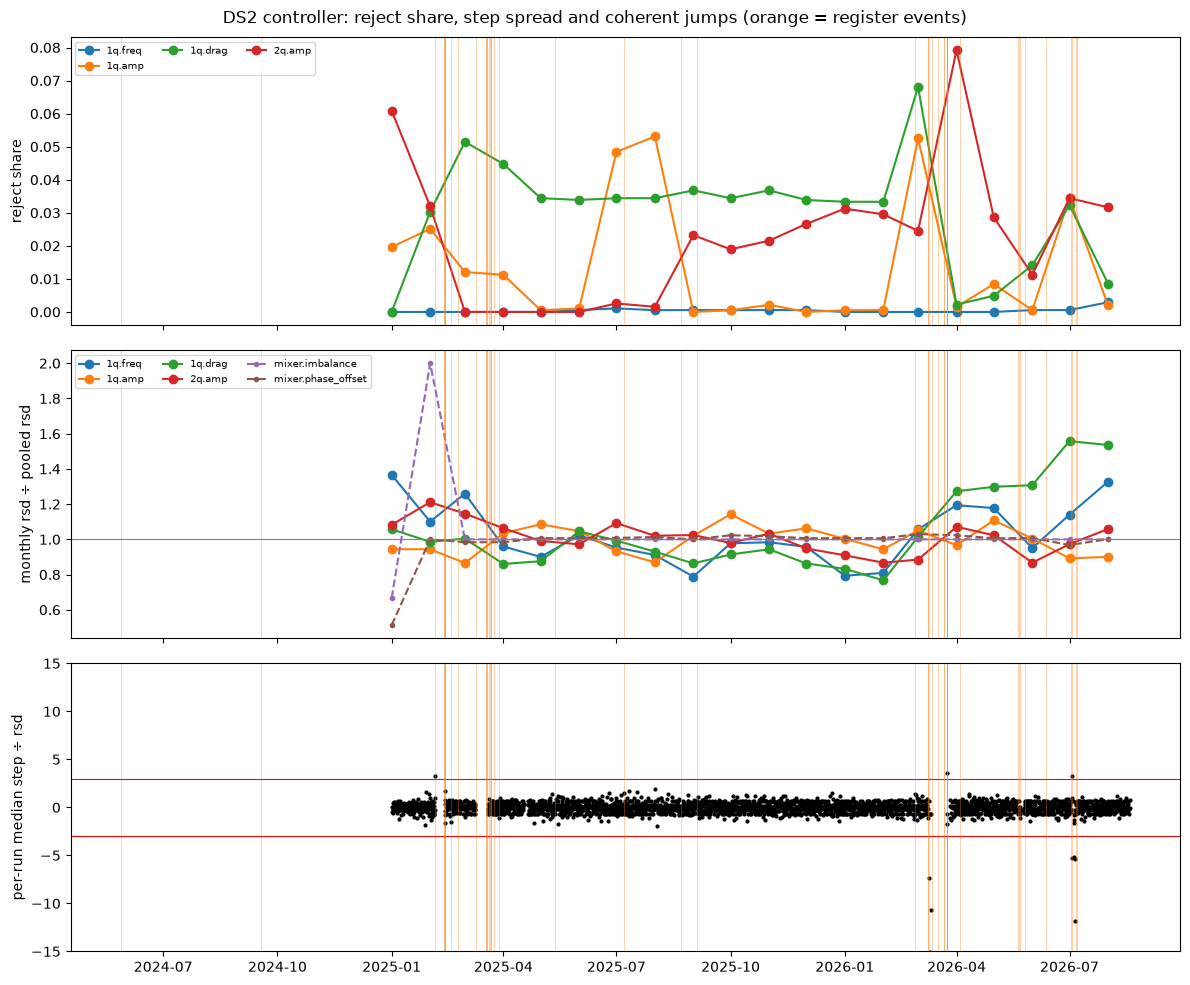

In [22]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
mt = mon.reset_index()
mt["t"] = mt["month"].dt.to_timestamp()
for k in KEYS[:4]:
    m = mt[mt["key"] == k]
    axes[0].plot(m["t"], m["reject_share"], marker="o", label=k)
    axes[1].plot(m["t"], m["rsd_ratio"], marker="o", label=k)
for k in KEYS[4:]:
    m = mt[mt["key"] == k]
    axes[1].plot(m["t"], m["rsd_ratio"], marker=".", ls="--", label=k)
axes[0].set_ylabel("reject share")
axes[1].set_ylabel("monthly rsd ÷ pooled rsd")
axes[1].axhline(1, color="grey", lw=0.8)
axes[2].scatter(score["at"], score["median_z"], s=4, color="k")
for s in (-THR, THR):
    axes[2].axhline(s, color="r", lw=0.8)
for e in reg["event_at"]:
    for ax in axes:
        ax.axvline(e, color="tab:orange", lw=0.5, alpha=0.5)
axes[2].set_ylabel("per-run median step ÷ rsd")
axes[2].set_ylim(-15, 15)
for ax in axes[:2]:
    ax.legend(fontsize=7, ncol=3)
fig.suptitle("DS2 controller: reject share, step spread and coherent jumps (orange = register events)")
fig.tight_layout()
fig.savefig(REPO_ROOT / "docs/figures/eda/b2_ds2_controller.png", dpi=120)
plt.show()


**Results.**

- Figure: [b2_ds2_controller.png](../../docs/figures/eda/b2_ds2_controller.png).

## Conclusion

| Result | Status |
|---|---|
| `paths.writer_stage` lists every stage where each parameter's changes land, including `benchmarking` for `mean_z_map_args` | Use `writer_stage`; take the writer of one change from the run map |
| No-run `snap_before` snapshots are pre-run saves, and so are four of the five big unregistered ones | In `periods.py` (`UNTRACKED_DS2_OTHER`) |
| Open 1q rows are mostly freq_shift qubits; most of the rest are a fixed qubit group losing a writing step with no id or warning | Not attempts |
| Rabi only writes amp in its > 1 reset, so a `rabi` id isn't an amp attempt | `STEPS_1Q` holds the writing steps; the run map's `measured` uses it |
| DS2 has no DC bias change after 2026-05-25 22:01:25 | Take DC bias from `output_info` after it |
| Drive `scale` is complex or float, with imaginary part always 0 | Use the real part |
| Settled reject shares: 1q amp 0.009483, drag 0.02708, freq 0.0004044, 2q 0.02171 | Pooled censoring well below 10% |
| Rejections cluster: Q26 has 695 of 866 rejected drag rows, couplings 14-15 and 19-11 have 377 of 704 rejected 2q rows | Evaluate censoring per entity |
| 1q and 2q controller step noise (lag-1 upper bound, conditional on acceptance) | 1679 `ds2` rows in `noise_floor.parquet` |
| Mixer steps sit on the search grid (imbalance 0.0006, phase offset 1e-12, DC bias 26 or 27) | No mixer noise rows; mixer step spread can't show drift |
| Coherent jumps above threshold 2 all match the register (chance 0.136), 15 of 21 without `INCIDENTS` and `F01_FLAGS`; nothing independent marks the 2026-07-02 onset | No unexplained change point |
| 1q amp steps share a chip-wide per-run offset that the next run undoes (chip median sd 0.559 against 0.207, lag-1 −0.524); it's 89 of the 100 unmatched runs above threshold 1 | Remove the run's chip median before reading 1q amp steps as local |
| Steps are larger after the 2026 thermal cycle (post / pre robust sd freq 1.234, drag 1.526, `cr_scale_re` 2.192), and `cr_scale` only turns its phase (\|z\| unchanged in 1.000 of steps) | Stratify at 2026-03-24; profile `cr_scale` as a phase |
